# FOMO score for BTC investors: 15 expert-statement features + HMM

**Notebook structure**

| Section | Content |
|---|---|
| 1 | Imports |
| 2 | Load data |
| 3 | Data exploration and checks |
| 4 | Descriptive statistics |
| 5 | Choosing the time-window frame: market context |
| 6 | Feature construction (15 features, at least one per expert statement) |
| 7 | Composite FOMO score (0–1 normalization, correlation pruning, weights, HMM) |
| 8 | Applying the pipeline and visualizing results |
| **9** | **Run the pipeline**: all parameters and run commands live here |
| — | Appendix (separate notebook `FOMO_appendix.ipynb`): 10 HMM diagnostics, 11 label-free validation results, 12 limitations, 13 file list, 14 validation code |

Sections 1–8 only **define functions**. Every parameter is assigned in **section 9**, one per line. To try another configuration, edit the values in section 9 and re-run the cells below.

Each section starts with a markdown heading, so it can be collapsed or expanded in Jupyter / JupyterLab / VS Code.

## 1. Imports

In [1]:
import json
import time
import zlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

pd.options.mode.chained_assignment = None
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)

# Shared colour palette for all charts
COLORS = {"ink": "#14213d", "muted": "#6b7280", "grid": "#e4e2dc", "blue": "#2a78d6",
          "orange": "#eb6834", "aqua": "#1baf7a", "red": "#c4461a",
          "Low": "#f6c9b3", "Medium": "#f0905f", "High": "#c4461a"}
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": COLORS["grid"], "axes.axisbelow": True})

## 2. Load data

Read the two files: daily BTC prices and the trade log. Normalize data types and sort by time.

In [2]:
def load_data(data_dir):
    """Read the market data and the trade log."""
    data_dir = Path(data_dir)
    market = pd.read_csv(data_dir / "btc_market_ohlcv.csv", parse_dates=["timestamp"])
    market = market.sort_values("timestamp").drop_duplicates("timestamp").set_index("timestamp")
    trades = pd.read_csv(data_dir / "btc_trade_log.csv", parse_dates=["timestamp"])
    trades["side"] = trades["side"].str.upper().str.strip()
    trades = trades.sort_values(["investor_id", "timestamp", "order_id"]).reset_index(drop=True)
    return market, trades

## 3. Data exploration and checks

- **Hard checks** (offending rows are dropped): missing values, invalid side, quantity or price ≤ 0, duplicate orders, duplicate rows, outside the market period, price outside the low–high range.
- **Soft checks** (report only): `amount` = price × quantity, cash and position ledgers, fee rate, fill price = close, trades per day, missing market days.

In [3]:
def check_data(market, trades):
    """Return (cleaned trades, table of check results)."""
    t = trades.copy()
    rows = []
    hard = {
        "Missing values": t[["investor_id", "timestamp", "side", "price", "quantity"]].isna().any(axis=1),
        "Invalid side": ~t["side"].isin(["BUY", "SELL"]),
        "Price or quantity <= 0": (t["price"] <= 0) | (t["quantity"] <= 0),
        "Duplicate order_id": t["order_id"].duplicated(),
        "Duplicate row": t.drop(columns="order_id").duplicated(),
        "Outside market period": ~t["timestamp"].between(market.index.min(), market.index.max()),
    }
    lo = market["low"].reindex(t["timestamp"]).to_numpy()
    hi = market["high"].reindex(t["timestamp"]).to_numpy()
    hard["Price outside low-high range"] = pd.Series((t["price"].to_numpy() < lo * 0.999) |
                                                  (t["price"].to_numpy() > hi * 1.001), index=t.index)
    bad = pd.Series(False, index=t.index)
    for name, mask in hard.items():
        rows.append(("Hard", name, int(mask.sum())))
        bad |= mask

    g = t.groupby("investor_id")
    sign = np.where(t["side"] == "BUY", -1.0, 1.0)
    cash_exp = g["cash_after"].shift() + sign * t["amount"] - t["fee"]
    pos_exp = g["btc_position_after"].shift().fillna(0) - sign * t["quantity"]
    close = market["close"].reindex(t["timestamp"]).to_numpy()
    soft = {
        "amount differs from price x quantity": int((np.abs(t["amount"] - t["price"] * t["quantity"]) > 1e-3 * t["amount"]).sum()),
        "Cash ledger mismatch": int((np.abs(cash_exp - t["cash_after"]) > 0.01).sum()),
        "Position ledger mismatch": int((np.abs(pos_exp - t["btc_position_after"]) > 1e-6).sum()),
        "Negative cash": int((t["cash_after"] < -1e-6).sum()),
        "Negative position": int((t["btc_position_after"] < -1e-9).sum()),
        "Fee rate (unique)": ", ".join(f"{x:.4%}" for x in sorted((t["fee"] / t["amount"]).round(6).unique())[:3]),
        "% of trades at the close price": f"{np.isclose(t['price'].to_numpy(), close).mean():.1%}",
        "Max trades / investor / day": int(t.groupby(["investor_id", "timestamp"]).size().max()),
        "Missing market days": int(len(pd.date_range(market.index.min(), market.index.max())) - len(market)),
    }
    for name, val in soft.items():
        rows.append(("Soft", name, val))
    report = pd.DataFrame(rows, columns=["Type", "Check", "Result"])
    clean = t[~bad].reset_index(drop=True)
    return clean, report

## 4. Descriptive statistics

In [4]:
def describe_data(market, trades):
    """Descriptive statistics for the market and the investors."""
    c = market["close"]
    per_inv = trades.groupby("investor_id")
    q = trades.assign(q=trades["timestamp"].dt.to_period("Q")).groupby(["investor_id", "q"]).size()
    first_buy = per_inv.head(1)
    init_cash = first_buy["cash_after"] + first_buy["amount"] + first_buy["fee"]
    summary = pd.Series({
        "Market days": len(market),
        "Period": f"{market.index.min().date()} -> {market.index.max().date()}",
        "Price first / min / max / last (USD)": f"{c.iloc[0]:,.0f} / {c.min():,.0f} / {c.max():,.0f} / {c.iloc[-1]:,.0f}",
        "Std. dev. of daily returns": f"{c.pct_change().std():.2%}",
        "Trades": f"{len(trades):,}",
        "Investors": trades["investor_id"].nunique(),
        "Share of buys": f"{(trades['side'] == 'BUY').mean():.1%}",
        "Trades / investor (median)": int(per_inv.size().median()),
        "Trades / investor / quarter (median)": int(q.median()),
        "Implied initial capital (median, USD)": f"{init_cash.median():,.0f}",
    }, name="Value").to_frame()
    by_side = trades.groupby("side")["amount"].describe()[["count", "mean", "25%", "50%", "75%", "max"]]
    by_year = trades.groupby(trades["timestamp"].dt.year).agg(
        so_lenh=("order_id", "size"), ty_le_mua=("side", lambda s: (s == "BUY").mean()))
    return summary, by_side, by_year


def plot_overview(market, trades):
    """BTC price, trades per month, distribution of trades per investor."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].plot(market.index, market["close"] / 1000, color=COLORS["ink"])
    axes[0].set_title("BTC price (thousand USD)")
    monthly = trades.set_index("timestamp").groupby([pd.Grouper(freq="ME"), "side"]).size().unstack(fill_value=0)
    axes[1].bar(monthly.index, monthly.get("BUY", 0), width=25, color=COLORS["blue"], label="BUY")
    axes[1].bar(monthly.index, monthly.get("SELL", 0), width=25, bottom=monthly.get("BUY", 0),
                color=COLORS["orange"], label="SELL")
    axes[1].set_title("Trades per month"); axes[1].legend(frameon=False)
    axes[2].hist(trades.groupby("investor_id").size(), bins=40, color=COLORS["blue"])
    axes[2].set_title("Trades per investor")
    plt.tight_layout(); plt.show()

## 5. Choosing the time-window frame: market context

**Market state of each day.** Uses closing prices up to the end of that day only. Trades fill at the close price, so the investor has already seen this price.

| State | How it is determined | Parameters | Rationale |
|---|---|---|---|
| Warm-up | First `WARMUP_DAYS` days, not enough history, no label | `WARMUP_DAYS` | Design choice (a minimum window is needed: Phillips, Shi & Yu 2015) |
| Hot | `RET_WINDOW`-day return, standardized by past volatility, above `Z_HOT` | `RET_WINDOW`, `VOL_WINDOW`, `Z_HOT` | 7 days: expert wording ("a strong week"). Volatility standardization follows Diaconaşu, Mehdian & Stoica (2022), who use daily GARCH residuals at a 2.5% tail threshold. 0.84 (top 20%) and 90 days are design choices with sensitivity checks |
| Fast drop | Standardized return below `-Z_HOT` | as above | as above |
| Near peak | Price ≥ `NEAR_PEAK` × the `PEAK_WINDOW`-day peak | `PEAK_WINDOW`, `NEAR_PEAK` | The peak is a psychological reference point: George & Hwang (2004), Li & Yu (2012), Jia et al. (2025) use the 52-week high for markets or portfolios. 45 days and 97% are design choices with sensitivity checks |
| Deep drawdown | Price < `DRAWDOWN` × the `PEAK_WINDOW`-day peak | `DRAWDOWN` | 15% decline following the bear-phase definition of Lunde & Timmermann (2004), as described by Kole & van Dijk (2010); applied here to the 45-day peak |
| Normal | None of the states above | | |

**Cycle windows.** The rally-onset day is the first hot day after at least `ONSET_GAP_DAYS` days without a hot day. Each window runs from the onset day to the day before the next onset. Windows are contiguous and do not overlap. The first window (from the first data day to before the first onset) is flagged as warm-up. The last window is still open because it ends where the data ends. The idea that "a phase needs a minimum length" appears in market-phase dating algorithms (Pagan & Sossounov 2003; Bry & Boschan 1971); the 30-day gap is a design choice, with sensitivity at 21 and 45.

In [5]:
def market_states(market, P):
    """Label the market state of each day (uses data up to that day only)."""
    c = market["close"]
    k = P["RET_WINDOW"]
    s = pd.DataFrame(index=market.index)
    s["close"] = c
    s["ret"] = c / c.shift(k) - 1
    # Past daily volatility (shift 1: excludes today)
    sigma = np.log(c).diff().rolling(P["VOL_WINDOW"], min_periods=P["WARMUP_DAYS"]).std().shift(1)
    s["z_ret"] = np.log(c / c.shift(k)) / (sigma * np.sqrt(k))
    s["peak_ref"] = c.rolling(P["PEAK_WINDOW"], min_periods=1).max()
    s["prox_peak"] = c / s["peak_ref"]
    warm = pd.Series(np.arange(len(s)) < P["WARMUP_DAYS"], index=s.index)
    ok = ~warm & s["z_ret"].notna()
    s["warmup"] = warm
    s["hot"] = ok & (s["z_ret"] > P["Z_HOT"])
    s["fast_drop"] = ok & (s["z_ret"] < -P["Z_HOT"])
    s["near_peak"] = ~warm & (s["prox_peak"] >= P["NEAR_PEAK"])
    s["deep_drawdown"] = ~warm & (s["prox_peak"] < P["DRAWDOWN"])
    s["normal"] = ~warm & ~(s["hot"] | s["fast_drop"] | s["near_peak"] | s["deep_drawdown"])
    s["state"] = np.select(
        [warm, s["hot"] & s["near_peak"], s["hot"], s["near_peak"], s["fast_drop"], s["deep_drawdown"]],
        ["warm-up", "hot + near peak", "hot", "near peak", "fast drop", "deep drawdown"], "normal")
    return s


def build_cycles(states, P):
    """Cut the time series into cycles, each starting on a rally-onset day."""
    onsets, last_hot = [], None
    for day, is_hot in states["hot"].items():
        if is_hot:
            if last_hot is None or (day - last_hot).days > P["ONSET_GAP_DAYS"]:
                onsets.append(day)
            last_hot = day
    first_day, last_day = states.index[0], states.index[-1]
    starts = [first_day] + [d for d in onsets if d > first_day]
    ends = [d - pd.Timedelta(days=1) for d in starts[1:]] + [last_day]
    cycles = pd.DataFrame({"cycle_id": range(len(starts)), "window_start": starts, "window_end": ends})
    cycles["n_days"] = (cycles["window_end"] - cycles["window_start"]).dt.days + 1
    cycles["is_warmup"] = cycles["cycle_id"].eq(0) & (cycles["window_start"] == first_day) & (
        len(onsets) == 0 or onsets[0] > first_day)
    cycles["is_open"] = cycles["cycle_id"].eq(cycles["cycle_id"].max())
    return cycles


def assign_cycle(dates, cycles):
    """Assign each day to the cycle that contains it."""
    starts = cycles["window_start"].to_numpy(dtype="datetime64[ns]")
    return np.searchsorted(starts, pd.to_datetime(dates).to_numpy(dtype="datetime64[ns]"), side="right") - 1


def cycle_market_summary(states, cycles):
    """Market-state statistics per cycle (warm-up days excluded)."""
    st = states.assign(cycle_id=assign_cycle(states.index, cycles))
    st = st[~st["warmup"]].assign(down=lambda d: d["fast_drop"] | d["deep_drawdown"])
    agg = st.groupby("cycle_id").agg(
        mkt_hot_share=("hot", "mean"), mkt_near_share=("near_peak", "mean"),
        n_hot_days=("hot", "sum"), n_near_days=("near_peak", "sum"), n_normal_days=("normal", "sum"), n_down_days=("down", "sum"),
        n_deep_days=("deep_drawdown", "sum"),
        mkt_return=("close", lambda x: x.iloc[-1] / x.iloc[0] - 1))
    out = cycles.merge(agg, left_on="cycle_id", right_index=True, how="left").fillna(
        {"mkt_hot_share": 0, "mkt_near_share": 0, "n_hot_days": 0, "n_near_days": 0, "n_normal_days": 0, "n_down_days": 0, "n_deep_days": 0})
    return out


def plot_market_context(states, cycles):
    """BTC price with market states and cycle boundaries."""
    fig, ax = plt.subplots(figsize=(16, 5))
    ax.plot(states.index, states["close"] / 1000, color=COLORS["ink"], lw=1.4, label="Close price")
    for flag, col, lab in [("hot", COLORS["orange"], "Hot"), ("fast_drop", COLORS["blue"], "Fast drop")]:
        m = states[flag]
        ax.scatter(states.index[m], states["close"][m] / 1000, s=8, color=col, label=lab, zorder=3)
    nm = states["near_peak"]
    ax.scatter(states.index[nm], states["close"][nm] / 1000 * 1.06, s=3, color=COLORS["red"], marker="v",
               label="Near peak", zorder=2)
    for d in cycles["window_start"].iloc[1:]:
        ax.axvline(d, color=COLORS["muted"], ls="--", lw=0.8)
    w = states.index[states["warmup"]]
    if len(w):
        ax.axvspan(w[0], w[-1], color=COLORS["grid"], alpha=0.8, label="Warm-up")
    ax.set_ylabel("thousand USD"); ax.set_title("Market context and cycles (dashed line = rally onset day)")
    ax.legend(frameon=False, ncol=5, loc="upper left")
    plt.tight_layout(); plt.show()

## 6. Feature construction

There is **a single layer of features**: for each investor × cycle pair we compute **15 features**, and every expert statement is represented by at least one feature. If a statement involves several quantities (size, frequency), it gets the corresponding number of features.

Every "baseline" uses only **earlier** trades or cycles (expanding + `shift(1)`).

| Group (expert statement) | Feature | How it is computed |
|---|---|---|
| S1. Chasing price: "silent for weeks… buys only after a sharp rise, at a price level never looked at before, with larger orders" | `f01_dormancy_before_trigger` | log((gap before the **first triggering buy** + 0.5) / (usual gap + 0.5)) |
| | `f02_trigger_vs_own_rate` | log of buy ratio on hot days / buy ratio on normal days of earlier cycles (smoothed +0.5) |
| | `f03_price_novelty` | position of the purchase price in the market's 365-day range (0 to 1), minus the position where they usually buy |
| | `f04_trigger_size_uplift` | log of median (% of cash per hot-day buy / their usual %) |
| S2. Near-peak reaction: "the closer to the peak, the more aggressively they buy, instead of cutting the position" | `f05_near_peak_dose_response` | Spearman between closeness to peak and % of cash per buy (≥ `MIN_BUYS_DOSE` buys) |
| | `f06_near_peak_share_excess` | % of buy value on near-peak days minus the market's % of near-peak days |
| | `f07_near_peak_net_flow` | buy ratio on near-peak days minus their own buy ratio on normal days |
| S3. Burst: "1–2 times a week rising to 8–10, almost all buys" | `f08_hot_week_burst_ratio` | log (largest 7-day trade count within **hot days** / usual weekly pace) |
| | `f09_burst_buy_skew` | buy ratio within burst trades minus usual buy ratio (smoothed +0.5) |
| S4. Deployment: "holds cash for months, then deploys most of it within days, right as the price surges" | `f10_cash_hoard_vs_own` | cash / capital (cash + **cost basis** of BTC, no market price) averaged over the 90 days before the trigger, minus their usual level |
| | `f11_deploy_speed` | % of cash deployed within the 7 days up to the first triggering buy |
| | `f12_hot_notional_excess` | % of buy value falling on hot days minus the market's % of hot days |
| S5. After the run-up: "little activity, or panic selling" | `f13_post_peak_silence` | log (earlier normal-day trading pace / pace while the price falls) |
| | `f14_panic_sell_rate` | number of panic sells (selling during a deep drawdown after a near-peak buy within 120 days) per deep-drawdown market day |
| S6. Sequence: "long inactivity → burst of near-peak buying → little activity or panic selling" | `f15_sequence_stages` | (triggering buy after dormancy + burst buy near the peak + panic sell or quiet period after the burst) / 3 |

**Missing-data convention.** No opportunity (e.g. a cycle with no hot day) or no personal baseline yet: the feature is `NaN` and is excluded from the score (weights of the remaining features are renormalized). Opportunity but no action (e.g. hot days but no buy), or a cycle with no trades: the feature is 0, which is evidence of "no behaviour". The two cases are separated by the column `low_<feature name>`.

**No leakage:** every feature of a cycle uses only trades inside the cycle and earlier history. The "silence after a buying burst" event is recorded on the **day the silence is confirmed** (`QUIET_DAYS` days after the burst).

In [6]:
# ===== 15 features: grouped by expert statement, with hidden-dimension tag =====
# P = relative to personal baseline; M = relative to market context; P+M = both
GROUPS = {"S1": "Chasing price", "S2": "Near-peak reaction", "S3": "Trading burst",
          "S4": "Cash deployment", "S5": "After the run-up", "S6": "Behaviour sequence"}


FEATURES = {
    "f01_dormancy_before_trigger": ("S1", "P"),
    "f02_trigger_vs_own_rate": ("S1", "P"),
    "f03_price_novelty": ("S1", "P+M"),
    "f04_trigger_size_uplift": ("S1", "P"),
    "f05_near_peak_dose_response": ("S2", "M"),
    "f06_near_peak_share_excess": ("S2", "M"),
    "f07_near_peak_net_flow": ("S2", "P"),
    "f08_hot_week_burst_ratio": ("S3", "P"),
    "f09_burst_buy_skew": ("S3", "P"),
    "f10_cash_hoard_vs_own": ("S4", "P"),
    "f11_deploy_speed": ("S4", "P"),
    "f12_hot_notional_excess": ("S4", "M"),
    "f13_post_peak_silence": ("S5", "P"),
    "f14_panic_sell_rate": ("S5", "M"),
    "f15_sequence_stages": ("S6", "P+M"),
}


FEAT = list(FEATURES)


def trade_features(trades, states, cycles, P):
    """Per-trade features. Every comparison baseline uses only trades/days BEFORE that trade (expanding, shift 1)."""
    t = trades.sort_values(["investor_id", "timestamp", "order_id"]).reset_index(drop=True)
    t = t.join(states[["hot", "fast_drop", "near_peak", "deep_drawdown", "normal", "warmup", "prox_peak"]], on="timestamp")
    t["cycle_id"] = assign_cycle(t["timestamp"], cycles)
    buy = t["side"].eq("BUY")
    sell = ~buy
    t["is_buy"] = buy.astype(int)

    # Purchase price position within the market's 365-day range (0 = low, 1 = high), using prices up to the trade date only
    c = states["close"]
    rmax = c.rolling(P["PRICE_RANGE_DAYS"], min_periods=P["PRICE_RANGE_MIN"]).max()
    rmin = c.rolling(P["PRICE_RANGE_DAYS"], min_periods=P["PRICE_RANGE_MIN"]).min()
    hi = rmax.reindex(t["timestamp"]).to_numpy(); lo = rmin.reindex(t["timestamp"]).to_numpy()
    t["price_pos"] = np.where(hi > lo, np.clip((t["price"].to_numpy() - lo) / np.where(hi > lo, hi - lo, 1), 0, 1), np.nan)

    # Order size as % of available cash, vs. the investor's own earlier usual level
    t["cash_before"] = np.where(buy, t["cash_after"] + t["amount"] + t["fee"], t["cash_after"] - t["amount"] + t["fee"])
    t["cash_frac"] = (t["amount"] / t["cash_before"]).where(buy)
    gb = t[buy].groupby("investor_id")
    t.loc[buy, "usual_cash_frac"] = gb["cash_frac"].transform(lambda x: x.expanding().median().shift(1))
    t["size_rel"] = t["cash_frac"] / t["usual_cash_frac"]

    # Silence before the trade
    t["gap_before"] = t.groupby("investor_id")["timestamp"].diff().dt.days
    t["usual_gap"] = t.groupby("investor_id")["gap_before"].transform(lambda x: x.expanding().median().shift(1))
    t["dormant_before"] = ((t["gap_before"] >= P["DORMANT_DAYS"]) &
                           (t["gap_before"] >= P["DORMANT_MULT"] * t["usual_gap"].fillna(0))).astype(int)

    # Usual buy ratio (earlier trades only), needs >= 5 earlier trades
    prior_n = t.groupby("investor_id").cumcount()
    prior_buys = t.groupby("investor_id")["is_buy"].cumsum() - t["is_buy"]
    t["usual_buy_share"] = (prior_buys / prior_n.where(prior_n >= 5)).astype(float)

    # Cash / capital: capital = cash + cost basis of BTC held (weighted average).
    # Market price is not used, so BTC price moves do not drive it.
    q_all = t["quantity"].to_numpy(); amt_all = t["amount"].to_numpy(); fee_all = t["fee"].to_numpy()
    pos_after = t["btc_position_after"].to_numpy(); buy_all = buy.to_numpy()
    cost_after = np.zeros(len(t))
    groups = t.groupby("investor_id", sort=False).indices
    for idx in groups.values():
        cost = 0.0
        for i in idx:
            if buy_all[i]:
                cost += amt_all[i] + fee_all[i]
            else:
                pos_before = pos_after[i] + q_all[i]
                cost *= 1.0 - (min(q_all[i] / pos_before, 1.0) if pos_before > 0 else 1.0)
            cost_after[i] = cost
    cap = t["cash_after"].to_numpy() + cost_after
    t["cash_share"] = np.where(cap > 0, t["cash_after"].to_numpy() / np.where(cap > 0, cap, 1), np.nan)

    # Last-N-days window: trade count (burst), % of cash deployed, cash before deployment
    n_burst = np.empty(len(t)); deploy = np.empty(len(t)); first_ts = np.empty(len(t), dtype="datetime64[ns]")
    hoard_mean = np.full(len(t), np.nan); usual_cash = np.full(len(t), np.nan)
    ts_all = t["timestamp"].to_numpy(); cash_all = t["cash_before"].to_numpy(); cs_all = t["cash_share"].to_numpy()
    for idx in groups.values():
        ts = ts_all[idx]; pos = np.arange(len(idx))
        s_b = np.searchsorted(ts, ts - np.timedelta64(P["BURST_DAYS"] - 1, "D"), side="left")
        s_d = np.searchsorted(ts, ts - np.timedelta64(P["DEPLOY_DAYS"] - 1, "D"), side="left")
        n_burst[idx] = pos - s_b + 1
        cum = np.concatenate([[0.0], np.cumsum(np.where(buy_all[idx], amt_all[idx], 0.0))])
        deploy[idx] = (cum[pos + 1] - cum[s_d]) / cash_all[idx][s_d]
        first_ts[idx] = ts[0]
        csum = np.concatenate([[0.0], np.cumsum(np.nan_to_num(cs_all[idx], nan=0.0))])
        q = np.searchsorted(ts, ts[s_d] - np.timedelta64(P["CASH_LOOKBACK_DAYS"], "D"), side="left")
        n_h = s_d - q
        hoard_mean[idx] = np.where(n_h > 0, (csum[s_d] - csum[q]) / np.maximum(n_h, 1), np.nan)
        usual_cash[idx] = np.where(q >= 3, csum[q] / np.maximum(q, 1), np.nan)
    t["hoard_mean_before"] = hoard_mean
    t["usual_cash_share"] = usual_cash
    t["trades_in_burst_window"] = n_burst
    t["deploy_window"] = np.clip(deploy, 0, 1)
    days_since_first = (t["timestamp"] - pd.to_datetime(first_ts)).dt.days
    weekly = prior_n / np.maximum(days_since_first / 7.0, 1.0)
    t["usual_weekly_rate"] = weekly.where(days_since_first >= 28)
    t["burst_ratio"] = t["trades_in_burst_window"] / np.maximum(t["usual_weekly_rate"], P["MIN_WEEKLY_RATE"])
    t["burst"] = ((t["trades_in_burst_window"] >= P["BURST_MIN_TRADES"]) &
                  (t["trades_in_burst_window"] >= P["BURST_MULT"] * t["usual_weekly_rate"].fillna(0))).astype(int)

    # Behaviour after the peak (looks backwards only)
    np_buy_date = t["timestamp"].where(buy & t["near_peak"])
    last_np_buy = np_buy_date.groupby(t["investor_id"]).transform(lambda x: x.ffill().shift(1))
    since_np = (t["timestamp"] - last_np_buy).dt.days
    t["panic_sell"] = (sell & t["deep_drawdown"] & (since_np <= P["PANIC_MEMORY_DAYS"])).astype(int)

    # Silence after a buying burst: the event is recorded on the confirmation day (burst buy + QUIET_DAYS)
    next_ts = t.groupby("investor_id")["timestamp"].shift(-1)
    gap_after = (next_ts - t["timestamp"]).dt.days
    quiet = buy & t["burst"].eq(1) & ((gap_after > P["QUIET_DAYS"]) | next_ts.isna())
    qe = t.loc[quiet, ["investor_id", "timestamp"]].copy()
    qe["event_date"] = qe["timestamp"] + pd.Timedelta(days=P["QUIET_DAYS"])
    qe = qe[qe["event_date"] <= states.index[-1]]
    qe["cycle_id"] = assign_cycle(qe["event_date"], cycles)
    quiet_events = qe.groupby(["investor_id", "cycle_id"]).size().rename("quiet_events")
    return t, quiet_events


def _spearman(x, y):
    if len(x) < 3 or np.std(x) == 0 or np.std(y) == 0:
        return np.nan
    return float(spearmanr(x, y)[0])


def window_features(tl, quiet_events, cycle_mkt, P):
    """15 raw features for each investor x cycle pair. NaN = not computable (excluded from the score).
    Column low_<name> = True when there was an opportunity but no behaviour (or no trades): zero evidence, not missing data."""
    key = ["investor_id", "cycle_id"]
    b = tl[tl["is_buy"] == 1]
    s = tl[tl["is_buy"] == 0]

    def notional_share(df, flag):
        return (df["amount"] * df[flag]).groupby([df["investor_id"], df["cycle_id"]]).sum() / df.groupby(key)["amount"].sum()

    first_cycle = tl.groupby("investor_id")["cycle_id"].min()
    all_c = cycle_mkt["cycle_id"].to_numpy()
    grid = pd.DataFrame([(i, c) for i, f in first_cycle.items() for c in all_c if c >= f], columns=key)
    w = grid.merge(cycle_mkt, on="cycle_id", how="left").set_index(key)
    agg = tl.groupby(key).agg(n_trades=("order_id", "size"), n_buys=("is_buy", "sum"))
    w = w.join(agg)
    cnt = lambda df, m: df[m].groupby([df["investor_id"], df["cycle_id"]]).size()
    w["hot_buys"] = cnt(b, b["hot"]); w["normal_buys"] = cnt(b, b["normal"])
    w["hot_trades"] = cnt(tl, tl["hot"]); w["near_trades"] = cnt(tl, tl["near_peak"])
    w["near_buys"] = cnt(b, b["near_peak"]); w["normal_trades"] = cnt(tl, tl["normal"])
    w["down_trades"] = cnt(tl, tl["fast_drop"] | tl["deep_drawdown"])
    w["panic_sells"] = s.groupby(key)["panic_sell"].sum()
    w["n_burst_trades"] = tl.groupby(key)["burst"].sum()
    for col in ["n_trades", "n_buys", "hot_buys", "normal_buys", "hot_trades", "near_trades", "near_buys", "normal_trades",
                "down_trades", "panic_sells", "n_burst_trades"]:
        w[col] = w[col].fillna(0)

    trig = b[b["hot"]]
    tb = trig.groupby(key).head(1).set_index(key)            # FIRST triggering buy of the cycle
    # S1 ------------------------------------------------------------------------------------
    w["f01_dormancy_before_trigger"] = np.log((tb["gap_before"] + 0.5) / (tb["usual_gap"] + 0.5))
    w["f04_trigger_size_uplift"] = np.log(trig.groupby(key)["size_rel"].median())
    # S2 ------------------------------------------------------------------------------------
    w["f05_near_peak_dose_response"] = b.groupby(key).apply(
        lambda d: _spearman(d["prox_peak"].to_numpy(), d["cash_frac"].to_numpy()) if len(d) >= P["MIN_BUYS_DOSE"] else np.nan,
        include_groups=False)
    w["f06_near_peak_share_excess"] = notional_share(b, "near_peak") - w["mkt_near_share"]
    # S3 ------------------------------------------------------------------------------------
    ht = tl[tl["hot"]]
    w["f08_hot_week_burst_ratio"] = np.log(ht.groupby(key)["burst_ratio"].max())
    bt = tl[tl["burst"] == 1]
    nb = bt.groupby(key).size(); sb = bt.groupby(key)["is_buy"].sum()
    w["f09_burst_buy_skew"] = (sb + 0.5) / (nb + 1) - bt.groupby(key)["usual_buy_share"].mean()
    # S4 ------------------------------------------------------------------------------------
    w["f10_cash_hoard_vs_own"] = tb["hoard_mean_before"] - tb["usual_cash_share"]
    w["f11_deploy_speed"] = tb["deploy_window"]
    w["f12_hot_notional_excess"] = notional_share(b, "hot") - w["mkt_hot_share"]
    # S6 ------------------------------------------------------------------------------------
    st1 = cnt(b, b["hot"] & (b["dormant_before"] == 1)).reindex(w.index).fillna(0) > 0
    st2 = cnt(b, (b["burst"] == 1) & b["near_peak"]).reindex(w.index).fillna(0) > 0
    st3 = (w["panic_sells"] > 0) | (quiet_events.reindex(w.index).fillna(0) > 0)
    w["f15_sequence_stages"] = (st1.astype(int) + st2.astype(int) + st3.astype(int)) / 3.0

    # Features that need the investor's own history: use EARLIER cycles (expanding + shift 1)
    w = w.reset_index().sort_values(key)
    g = w.groupby("investor_id")
    active = (w["n_trades"] > 0).astype(int)
    w["prior_active_cycles"] = active.groupby(w["investor_id"]).transform(lambda x: x.cumsum().shift(1)).fillna(0)
    w["has_baseline"] = w["prior_active_cycles"] >= P["MIN_PRIOR_CYCLES"]
    prior = lambda col: g[col].transform(lambda x: x.cumsum().shift(1))
    prior_normal_buys, prior_normal_days = prior("normal_buys"), prior("n_normal_days")
    prior_normal_trades, prior_normal_tr = prior("normal_trades"), prior("normal_trades")
    normal_rate = (prior_normal_buys + 0.5) / (prior_normal_days + 1.0)
    hot_rate = (w["hot_buys"] + 0.5) / (w["n_hot_days"] + 1.0)
    w["f02_trigger_vs_own_rate"] = np.log(hot_rate / normal_rate).where(w["has_baseline"] & (w["n_hot_days"] > 0))
    # f03: purchase price position in the 365-day market range, vs. where they usually buy
    pp = b.dropna(subset=["price_pos"]).groupby(key)["price_pos"].agg(["sum", "count"]).reindex(
        pd.MultiIndex.from_frame(w[key])).fillna(0).reset_index(drop=True)
    w["pp_sum"], w["pp_n"] = pp["sum"].to_numpy(), pp["count"].to_numpy()
    g = w.groupby("investor_id")
    prior_sum, prior_cnt = g["pp_sum"].transform(lambda x: x.cumsum().shift(1)), g["pp_n"].transform(lambda x: x.cumsum().shift(1))
    w["f03_price_novelty"] = (w["pp_sum"] / w["pp_n"].where(w["pp_n"] > 0) - prior_sum / prior_cnt.where(prior_cnt >= 5))
    # f07: buy ratio on near-peak days minus own buy ratio on normal days
    near_share = (w["near_buys"] + 0.5) / (w["near_trades"] + 1.0)
    prior_normal_buy_share = (prior_normal_buys + 0.5) / (prior_normal_trades + 1.0)
    w["f07_near_peak_net_flow"] = (near_share - prior_normal_buy_share).where(w["has_baseline"] & (w["near_trades"] > 0))
    # f13: earlier normal-day trading pace / pace during price declines (high = less action than usual)
    normal_tr_rate = (prior_normal_tr + 0.5) / (prior_normal_days + 1.0)
    down_tr_rate = (w["down_trades"] + 0.5) / (w["n_down_days"] + 1.0)
    w["f13_post_peak_silence"] = np.log(normal_tr_rate / down_tr_rate).where(w["has_baseline"] & (w["n_down_days"] > 0))
    # f14: panic sells per deep-drawdown market day (smoothed)
    w["f14_panic_sell_rate"] = ((w["panic_sells"] + 0.5) / (w["n_deep_days"] + 1.0)).where(w["n_deep_days"] > 0)

    # No opportunity -> NaN (excluded from the score). Opportunity but no action -> low (zero evidence).
    hot_opp, near_opp = w["n_hot_days"] > 0, w["n_near_days"] > 0
    no_trig = hot_opp & (w["hot_buys"] == 0)
    for f in ["f01_dormancy_before_trigger", "f02_trigger_vs_own_rate", "f04_trigger_size_uplift", "f08_hot_week_burst_ratio",
              "f10_cash_hoard_vs_own", "f11_deploy_speed", "f12_hot_notional_excess"]:
        w.loc[~hot_opp, f] = np.nan
    for f in ["f05_near_peak_dose_response", "f06_near_peak_share_excess", "f07_near_peak_net_flow"]:
        w.loc[~near_opp, f] = np.nan
    low = pd.DataFrame(False, index=w.index, columns=FEAT)
    for f in ["f01_dormancy_before_trigger", "f04_trigger_size_uplift", "f10_cash_hoard_vs_own", "f11_deploy_speed"]:
        low[f] = no_trig
    low["f07_near_peak_net_flow"] = near_opp & (w["near_trades"] == 0)
    low["f08_hot_week_burst_ratio"] = hot_opp & (w["hot_trades"] == 0)
    low["f09_burst_buy_skew"] = w["n_burst_trades"] == 0
    low["f12_hot_notional_excess"] = hot_opp & (w["n_buys"] == 0)
    low["f06_near_peak_share_excess"] = near_opp & (w["n_buys"] == 0)
    low = low.apply(lambda col: col | (w["n_trades"] == 0))        # no trades at all: every feature = 0
    for f in FEAT:
        w[f"low_{f}"] = low[f]
    return w.reset_index(drop=True)

## 7. Composite FOMO score

1. **Normalize to 0–1.** Each feature becomes a 0–1 rank (mid-rank) within a reference set made of all cycles **up to the current one**, counting only rows with trades. The direction is always "more FOMO = higher".
2. **Drop highly correlated features.** Spearman correlation matrix over **observed** cells (cells filled with 0 by convention are excluded, because they make all 'trigger' features spuriously correlated: all are 0 when there was no hot-day buy). For a pair with |ρ| ≥ `CORR_TH`: keep the less-missing feature, then the one less dominated by the market; the last feature of a group is never dropped. Recomputed at every cycle using data up to that cycle only.
3. **Weights.** Each expert statement gets an equal group weight (`W_S1`…`W_S6`), split evenly among the remaining features of the group, then multiplied by `(1 − η²)`. η² is the share of a feature's variance explained **by the market cycle alone** (ANOVA by cycle, no labels): high η² means all investors rise or fall together with the market, so the feature cannot isolate individuals and gets a lower weight. η² is also computed walk-forward.
4. **Feature score** = weighted sum of the normalized features (0–1 scale), over the features that have data.
5. **HMM.** One HMM shared by all investors, diagonal-Gaussian emissions (tolerates missing values), `HMM_K` states, with each person's cycles over time as the sequence. It is retrained at every cycle on data up to that cycle and uses only **forward-filtered probabilities** (no Viterbi, no smoothing). States are assigned from the emission profile (weighted mean feature level), not from the rule-based score. HMM score = expected FOMO level of the states under the filtered probabilities (the probability of the FOMO state alone saturates near 0/1 because features are assumed conditionally independent; it is still reported in the column `hmm_fomo_state_prob`).
6. **`fomo_score`** = 100 × (`W_FEATURE` × feature score + `W_HMM` × HMM score).
7. **Low/Medium/High levels.** The data dictionary suggests 40/70. The score is an average of ranks, so the scale is relative: with 40/70 thresholds, fewer than 1% of rows exceed 70. We therefore use percentile thresholds (`LEVEL_MODE = "quantile"`): Low below percentile `Q_LOW`, High above percentile `Q_HIGH`, with expanding percentiles over cycles for cycle scores and percentiles across investors for whole-period scores. Set `LEVEL_MODE = "dictionary"` to use 40/70.
8. **`confidence`** = 0.4 × distance to the threshold (in score standard deviations) + 0.3 × agreement between feature score and HMM score + 0.3 × enough data.
9. **`top_k_signal`**: the features contributing most to the feature score (normalized weight × (rank − 0.5)).
10. **Logistic regression (LR) is for explanation only, not scoring:** proxy labels come from the composite score itself (top 20% vs bottom 40%), so the LR reproduces the score and yields per-feature standardized coefficients.
11. **Whole period** = 0.6 × confidence-weighted mean of the 3 highest-scoring cycles + 0.4 × confidence-weighted mean of all cycles with trades (warm-up excluded).

In [7]:
# ===== 7. 0-1 normalization, high-correlation pruning, weights, HMM, composite score =====
def expanding_percentiles(w, cols):
    """0-1 rank within a reference set made of all cycles <= the current cycle (mid-rank).
    The reference set contains only rows with trades, so 'no trade' cells do not dilute the distribution."""
    out = pd.DataFrame(index=w.index, columns=cols, dtype=float)
    cyc = w["cycle_id"].to_numpy(); has = (w["n_trades"] > 0).to_numpy()
    for col in cols:
        v = w[col].to_numpy(dtype=float)
        ok = ~np.isnan(v) & has
        for k in np.unique(cyc):
            ref = np.sort(v[(cyc <= k) & ok])
            cur = (cyc == k) & ok
            if len(ref) == 0 or not cur.any():
                continue
            lo = np.searchsorted(ref, v[cur], "left"); hi = np.searchsorted(ref, v[cur], "right")
            out.loc[cur, col] = (lo + hi) / 2 / len(ref)
    return out


def normalize_features(w):
    """Raw features -> 0-1 rank. low -> 0; not computable -> NaN."""
    low = w[[f"low_{f}" for f in FEAT]].to_numpy()
    raw = w[FEAT].where(~pd.DataFrame(low, index=w.index, columns=FEAT))
    pct = expanding_percentiles(w.assign(**{f: raw[f] for f in FEAT}), FEAT)
    for j, f in enumerate(FEAT):
        pct.loc[low[:, j], f] = 0.0
    return pct


def eta_squared(pct, cyc, rows):
    """Share of each feature's variance explained by the market cycle alone (ANOVA, 0-1). No labels used."""
    out = {}
    for f in pct.columns:
        v = pct[f].to_numpy(dtype=float); ok = rows & ~np.isnan(v)
        if ok.sum() < 30 or len(np.unique(cyc[ok])) < 2:
            out[f] = 0.0; continue
        x, c = v[ok], cyc[ok]
        tot = ((x - x.mean()) ** 2).sum()
        means = pd.Series(x).groupby(c).transform("mean").to_numpy()
        out[f] = float(((means - x.mean()) ** 2).sum() / tot) if tot > 0 else 0.0
    return pd.Series(out)


def observed_percentiles(w, pct):
    """0-1 rank only in cells with observed behaviour (cells filled with 0 by the 'no action' convention are dropped)."""
    low = pd.DataFrame(w[[f"low_{f}" for f in FEAT]].to_numpy(), index=w.index, columns=FEAT)
    return pct.where(~low)


def prune_correlated(pct, obs, rows, eta2, P):
    """Drop highly correlated features: in each pair with |rho| >= CORR_TH keep the less-missing feature, then the one less dominated by the market.
    Correlation is computed on observed cells: cells filled with 0 by convention create spurious correlation among all 'trigger' features
    (all 0 when there was no hot-day buy). The last feature of an expert-statement group is never dropped."""
    d = obs[rows]
    if len(d) < P["CORR_MIN_ROWS"]:
        return list(FEAT), pd.DataFrame(columns=["feature_a", "feature_b", "spearman", "dropped"])
    C = d.corr(method="spearman", min_periods=P["CORR_MIN_PAIRS"])
    miss = pct[rows].isna().mean()
    pairs = [(a, b, C.loc[a, b]) for i, a in enumerate(FEAT) for b in FEAT[i + 1:]
             if np.isfinite(C.loc[a, b]) and abs(C.loc[a, b]) >= P["CORR_TH"]]
    pairs.sort(key=lambda x: -abs(x[2]))
    active, log = list(FEAT), []
    for a, b, r in pairs:
        if a not in active or b not in active:
            continue
        keep, drop = (a, b) if (miss[a], -(1 - eta2[a])) <= (miss[b], -(1 - eta2[b])) else (b, a)
        if sum(FEATURES[x][0] == FEATURES[drop][0] for x in active) <= 1:
            keep, drop = drop, keep
            if sum(FEATURES[x][0] == FEATURES[drop][0] for x in active) <= 1:
                continue
        active.remove(drop); log.append((a, b, round(float(r), 3), drop))
    return active, pd.DataFrame(log, columns=["feature_a", "feature_b", "spearman", "dropped"])


def feature_weights(active, eta2, P):
    """Weight = (group weight / number of remaining features in the group) x (1 - eta2). High eta2 = hard to separate the individual from the market."""
    gw = {g: P[f"W_{g}"] for g in GROUPS}
    wt = pd.Series(0.0, index=FEAT)
    for f in active:
        g = FEATURES[f][0]
        n_g = sum(FEATURES[x][0] == g for x in active)
        wt[f] = gw[g] / n_g * ((1 - eta2[f]) if P["USE_ETA2"] else 1.0) * P["MANUAL_MULT"].get(f, 1.0)
    return wt


def feature_score(pct, wt):
    """Weighted sum of the normalized features, computed over the features that have data."""
    v = pct[list(wt.index)].to_numpy(dtype=float); ww = wt.to_numpy()[None, :] * ~np.isnan(v)
    score = np.nansum(v * ww, axis=1) / np.maximum(ww.sum(axis=1), 1e-12)
    coverage = ww.sum(axis=1) / max(wt.sum(), 1e-12)
    return score, coverage, ww


# ---------- Diagonal-Gaussian HMM, tolerates missing values; uses forward-filtered probabilities only ----------
def _hmm_logb(X, M, mu, var):
    x0 = np.nan_to_num(X)[:, :, None, :]
    d = -0.5 * (M[:, :, None, :] * (np.log(2 * np.pi * var)[None, None] + (x0 - mu[None, None]) ** 2 / var[None, None])).sum(-1)
    return d


def _hmm_forward(logb, valid, pi, A):
    N, T, K = logb.shape
    mx = logb.max(-1, keepdims=True); B = np.exp(logb - mx)
    alpha = np.zeros((N, T, K)); c = np.ones((N, T)); ll = 0.0
    for t in range(T):
        prev = valid[:, t - 1] if t else np.zeros(N, bool)
        a = np.where((valid[:, t] & ~prev)[:, None], pi[None], 0.0)
        if t:
            a = np.where((valid[:, t] & prev)[:, None], alpha[:, t - 1] @ A, a)
        a = a * B[:, t]
        s = a.sum(-1); s = np.where(valid[:, t], np.maximum(s, 1e-300), 1.0)
        alpha[:, t] = np.where(valid[:, t, None], a / s[:, None], 0.0); c[:, t] = s
        ll += (np.log(s) + mx[:, t, 0] * valid[:, t])[valid[:, t]].sum()
    return alpha, B, c, ll


def _hash01(keys, t, r, salt):
    """Pseudo-random numbers in [0, 1) determined by (investor, cycle, restart): independent of how many other investors are in the sample."""
    with np.errstate(over="ignore"):
        x = (keys.astype(np.uint64)[:, None] * np.uint64(0x9E3779B97F4A7C15) + (t.astype(np.uint64)[None, :] + np.uint64(1)) * np.uint64(0xBF58476D1CE4E5B9)
             + np.uint64(r * 7919 + salt) * np.uint64(0x94D049BB133111EB))
        x ^= x >> np.uint64(30); x *= np.uint64(0xBF58476D1CE4E5B9)
        x ^= x >> np.uint64(27); x *= np.uint64(0x94D049BB133111EB)
        x ^= x >> np.uint64(31)
    return (x >> np.uint64(11)).astype(np.float64) / float(1 << 53)


def hmm_fit(X, valid, K, restarts, seed, iters, var_floor, keys):
    """Baum-Welch with a fixed number of iterations. X: (N, T, D) with NaN; valid: (N, T); keys: fixed id of each investor (for deterministic initialisation)."""
    N, T, D = X.shape
    M = (~np.isnan(X)).astype(float) * valid[:, :, None]
    rowmean = np.nanmean(np.where(valid[:, :, None], X, np.nan), axis=2)
    best = None
    for r in range(restarts):
        flat = rowmean[valid]
        cuts = np.nanquantile(flat, np.linspace(0, 1, K + 1)[1:-1])
        lab = np.digitize(rowmean, cuts)
        if r:
            tt = np.arange(T)
            flip = _hash01(keys, tt, r + 31 * seed, 1) < 0.15
            lab = np.where(flip, np.minimum((_hash01(keys, tt, r + 31 * seed, 2) * K).astype(int), K - 1), lab)
        mu = np.zeros((K, D)); var = np.zeros((K, D))
        Xv = np.where(valid[:, :, None], X, np.nan)
        for k in range(K):
            sel = (lab == k) & valid
            xs = Xv[sel]
            mu[k] = np.nanmean(xs, axis=0) if len(xs) else 0.5
            var[k] = np.maximum(np.nanvar(xs, axis=0) if len(xs) > 1 else 0.05, var_floor)
        mu = np.nan_to_num(mu, nan=0.5); var = np.nan_to_num(var, nan=0.05)
        pi = np.full(K, 1 / K); A = np.full((K, K), 0.2 / max(K - 1, 1)); np.fill_diagonal(A, 0.8)
        for _ in range(iters):
            logb = _hmm_logb(X, M, mu, var)
            alpha, B, c, ll = _hmm_forward(logb, valid, pi, A)
            beta = np.zeros_like(alpha)
            for t in range(T - 1, -1, -1):
                nxt = valid[:, t + 1] if t < T - 1 else np.zeros(N, bool)
                bt = np.ones((N, K))
                if t < T - 1:
                    tmp = (B[:, t + 1] * beta[:, t + 1]) @ A.T / c[:, t + 1, None]
                    bt = np.where(nxt[:, None], tmp, 1.0)
                beta[:, t] = np.where(valid[:, t, None], bt, 0.0)
            gam = alpha * beta; gam /= np.maximum(gam.sum(-1, keepdims=True), 1e-300)
            xi = np.zeros((K, K))
            for t in range(T - 1):
                ok = valid[:, t] & valid[:, t + 1]
                if not ok.any():
                    continue
                z = alpha[ok, t][:, :, None] * A[None] * (B[ok, t + 1] * beta[ok, t + 1])[:, None, :]
                z /= np.maximum(z.sum((1, 2), keepdims=True), 1e-300)
                xi += z.sum(0)
            start = valid & ~np.concatenate([np.zeros((N, 1), bool), valid[:, :-1]], axis=1)
            pi = gam[start].sum(0) + 1e-6; pi /= pi.sum()
            A = xi + 1e-6; A /= A.sum(1, keepdims=True)
            wgt = gam[:, :, :, None] * M[:, :, None, :]
            den = np.maximum(wgt.sum((0, 1)), 1e-9)
            mu = (wgt * np.nan_to_num(X)[:, :, None, :]).sum((0, 1)) / den
            var = np.maximum((wgt * (np.nan_to_num(X)[:, :, None, :] - mu[None, None]) ** 2).sum((0, 1)) / den, var_floor)
        if best is None or ll > best["ll"]:
            best = dict(pi=pi, A=A, mu=mu, var=var, ll=ll)
    return best


def hmm_filter(model, X, valid):
    M = (~np.isnan(X)).astype(float) * valid[:, :, None]
    alpha, _, _, ll = _hmm_forward(_hmm_logb(X, M, model["mu"], model["var"]), valid, model["pi"], model["A"])
    return alpha, ll


def hmm_bic(model, ll, n_obs, K, D):
    return float(-2 * ll + (K - 1 + K * (K - 1) + 2 * K * D) * np.log(n_obs))


def score_cycles(w, P):
    """FOMO score for each investor x cycle pair: 0.5 x feature score + 0.5 x HMM score, walk-forward over cycles."""
    pct = normalize_features(w)
    obs = observed_percentiles(w, pct)
    cyc = w["cycle_id"].to_numpy(); cycles_u = np.unique(cyc)
    inv_ids = w["investor_id"].astype("category"); inv_code = inv_ids.cat.codes.to_numpy()
    inv_key = np.array([zlib.crc32(str(x).encode()) for x in inv_ids.cat.categories], dtype=np.uint64)
    N, T, D = inv_ids.cat.categories.size, int(cycles_u.max()) + 1, len(FEAT)
    valid_grid = np.zeros((N, T), bool); valid_grid[inv_code, cyc] = True
    Xfull = np.full((N, T, D), np.nan); Xfull[inv_code, cyc] = pct.to_numpy()
    use_rows = ((w["n_trades"] > 0) & ~w["is_warmup"]).to_numpy()

    S = np.full(len(w), np.nan); cov = np.full(len(w), np.nan); H_level = np.full(len(w), np.nan); H_state = np.full(len(w), np.nan)
    contrib = np.full((len(w), D), np.nan); log_k = {}
    for k in cycles_u:
        rows_k = use_rows & (cyc <= k)
        eta2 = eta_squared(pct, cyc, rows_k) if len(np.unique(cyc[rows_k])) >= P["ETA2_MIN_CYCLES"] and rows_k.sum() >= P["CORR_MIN_ROWS"] \
            else pd.Series(0.0, index=FEAT)
        active, drop_log = prune_correlated(pct, obs, rows_k, eta2, P)
        wt = feature_weights(active, eta2, P)
        cur = cyc == k
        s_k, c_k, ww = feature_score(pct[cur], wt)
        S[cur], cov[cur] = s_k, c_k
        wn = ww / np.maximum(ww.sum(axis=1, keepdims=True), 1e-12)
        pc = pct[cur].to_numpy()
        contrib[cur] = np.where(np.isnan(pc), np.nan, wn * (pc - 0.5))
        # HMM: train on all cycles <= k, forward-filter, take the probabilities at cycle k
        if rows_k.sum() >= P["HMM_MIN_ROWS"]:
            ai = [FEAT.index(f) for f in active]
            Xk = Xfull[:, :k + 1][:, :, ai]; vk = valid_grid[:, :k + 1]
            model = hmm_fit(Xk, vk, P["HMM_K"], P["HMM_RESTARTS"], P["RANDOM_STATE"], P["HMM_ITERS"], P["HMM_VAR_FLOOR"], inv_key)
            alpha, ll = hmm_filter(model, Xk, vk)
            wa = wt[active].to_numpy(); wa = wa / wa.sum()
            level_k = model["mu"] @ wa                                  # mean FOMO level of each state
            post = alpha[inv_code[cur], k]                              # forward-filtered probability at cycle k
            H_level[cur] = post @ level_k
            H_state[cur] = post[:, int(np.argmax(level_k))]
            log_k[int(k)] = dict(active=active, eta2=eta2.round(3).to_dict(), weights=wt.round(4).to_dict(),
                                 drops=drop_log.values.tolist(), state_level=[round(float(x), 3) for x in level_k],
                                 trans=model["A"].round(3).tolist(), pi=model["pi"].round(3).tolist(), ll=float(ll))
        else:
            log_k[int(k)] = dict(active=active, eta2=eta2.round(3).to_dict(), weights=wt.round(4).to_dict(),
                                 drops=drop_log.values.tolist())
    # Final score: 0.5 x feature score + 0.5 x HMM score (HMM without enough data -> feature score only)
    parts = np.column_stack([S, H_level]); ww_ = np.array([P["W_FEATURE"], P["W_HMM"]])
    valid_p = ~np.isnan(parts)
    score = 100 * np.nansum(parts * ww_, axis=1) / np.maximum((valid_p * ww_).sum(axis=1), 1e-12)
    res = w.copy()
    res["feature_score"], res["hmm_score"], res["hmm_fomo_state_prob"], res["feature_coverage"] = S, H_level, H_state, cov
    for f in FEAT:
        res[f"pct_{f}"] = pct[f].round(4)
    res["fomo_score"] = np.round(np.clip(score, 0, 100), 2)
    res = assign_levels(res, P)
    # confidence = distance from threshold + agreement between feature score and HMM + enough data
    # cumulative SD: cycle k uses only scores of cycles <= k (no look-ahead)
    sd = np.ones(len(res))
    cyc_arr = res["cycle_id"].to_numpy(); fs = res["fomo_score"].to_numpy()
    for k in cycles_u:
        m_ = use_rows & (cyc_arr <= k) & ~np.isnan(fs)
        v_ = float(np.std(fs[m_])) if m_.sum() > 1 else 1.0
        sd[cyc_arr == k] = v_ or 1.0
    d = np.minimum(np.abs(res["fomo_score"] - res["thr_low"]), np.abs(res["fomo_score"] - res["thr_high"]))
    margin = np.clip(d / (P["CONF_MARGIN_SD"] * sd), 0, 1)
    agree = 1 - np.clip(np.abs(res["feature_score"] - res["hmm_score"]).fillna(0) / 0.25, 0, 1)
    data_ok = np.clip(res["n_trades"] / P["CONF_MIN_TRADES"], 0, 1) * np.where(res["has_baseline"], 1.0, 0.75) * np.clip(res["feature_coverage"].fillna(0), 0, 1)
    data_ok = data_ok * np.where(res["is_warmup"], 0.5, 1.0)
    res["confidence"] = np.round(np.clip(0.4 * margin + 0.3 * agree + 0.3 * data_ok, 0, 1), 3)
    cdf = pd.DataFrame(contrib, index=res.index, columns=FEAT)
    top = np.argsort(-np.nan_to_num(cdf.to_numpy(), nan=-9), axis=1)[:, :3]
    vals = np.take_along_axis(np.nan_to_num(cdf.to_numpy(), nan=-9), top, axis=1)
    names = np.array(FEAT)
    for i in range(3):
        res[f"top_{i+1}_signal"] = np.where(vals[:, i] > 0, names[top[:, i]], "none")
    res["notes"] = _notes(res, P)
    return res, cdf, log_k


def assign_levels(res, P):
    """Attach the Low/Medium/High level and the two thresholds used for each row.
    dictionary: fixed 40/70 thresholds (data dictionary); quantile: thresholds are expanding percentiles of the scores of rows with trades up to that cycle."""
    res = res.copy()
    cyc = res["cycle_id"].to_numpy(); sc = res["fomo_score"].to_numpy()
    use = ((res["n_trades"] > 0) & ~res["is_warmup"]).to_numpy()
    lo, hi = np.full(len(res), float(P["LEVEL_LOW"])), np.full(len(res), float(P["LEVEL_HIGH"]))
    if P["LEVEL_MODE"] == "quantile":
        for k in np.unique(cyc):
            ref = sc[(cyc <= k) & use]
            if len(ref) >= P["CORR_MIN_ROWS"]:
                lo[cyc == k], hi[cyc == k] = np.quantile(ref, P["Q_LOW"]), np.quantile(ref, P["Q_HIGH"])
    res["thr_low"], res["thr_high"] = lo, hi
    res["fomo_level"] = np.where(sc > hi, "High", np.where(sc >= lo, "Medium", "Low"))
    return res


def _notes(res, P):
    notes = []
    for r in res.itertuples():
        bits = []
        if r.is_warmup: bits.append("warm-up cycle: market state partly undefined")
        if r.is_open: bits.append("open cycle (ends at data end)")
        if r.n_trades == 0: bits.append("no trades in cycle")
        elif r.n_trades < 3: bits.append(f"thin cycle ({int(r.n_trades)} trades)")
        if not r.has_baseline: bits.append("no personal baseline yet")
        if r.n_hot_days == 0: bits.append("no hot days in cycle")
        notes.append("; ".join(bits))
    return notes


def investor_rollup(res, contrib, P):
    """Whole-period score = ROLL_W_INTENSITY x (mean of top-K cycles) + ROLL_W_RECURRENCE x (mean of all cycles), both confidence-weighted; warm-up excluded."""
    use = (res["n_trades"] > 0) & ~res["is_warmup"]
    act = res[use].copy()
    act["w_"] = act["confidence"] + 1e-6
    act["h0"] = act["hmm_score"].fillna(act["feature_score"])
    # intensity: weighted mean of the TOP_K highest-scoring cycles; recurrence: mean of all cycles
    act["rk"] = act.groupby("investor_id")["fomo_score"].rank(method="first", ascending=False)
    wi, wr = P["ROLL_W_INTENSITY"], P["ROLL_W_RECURRENCE"]
    def _wm(d, col):
        return (d[col] * d["w_"]).sum() / d["w_"].sum()
    rows = {}
    for iid, d in act.groupby("investor_id"):
        top = d[d["rk"] <= P["TOP_K_CYCLES"]]
        rows[iid] = {c: wi * _wm(top, src) + wr * _wm(d, src) for c, src in
                     [("score", "fomo_score"), ("feat", "feature_score"), ("hmm", "h0")]}
        rows[iid].update(conf_win=d["confidence"].mean(), n_active_cycles=len(d),
                         peak_cycle_score=d["fomo_score"].max(), n_trades=d["n_trades"].sum())
    inv = pd.DataFrame.from_dict(rows, orient="index")
    # feat/hmm are on a 0-1 scale, score on a 0-100 scale: unchanged
    allinv = pd.Index(sorted(res["investor_id"].unique()))
    inv = inv.reindex(allinv)
    nodata = inv["score"].isna()
    if nodata.any():                       # investor with no active cycle outside warm-up
        fb = res.groupby("investor_id").agg(score=("fomo_score", "mean"), feat=("feature_score", "mean"),
                                           hmm=("hmm_score", "mean"), n_trades=("n_trades", "sum"))
        for c in ["score", "feat", "hmm", "n_trades"]:
            inv.loc[nodata, c] = fb.loc[inv.index[nodata], c]
        inv["conf_win"] = inv["conf_win"].fillna(0.2); inv["n_active_cycles"] = inv["n_active_cycles"].fillna(0)
        inv["peak_cycle_score"] = inv["peak_cycle_score"].fillna(inv["score"])
    sc = inv["score"].to_numpy()
    if P["LEVEL_MODE"] == "quantile":
        lo_t, hi_t = np.quantile(sc, P["Q_LOW"]), np.quantile(sc, P["Q_HIGH"])
    else:
        lo_t, hi_t = float(P["LEVEL_LOW"]), float(P["LEVEL_HIGH"])
    inv["fomo_level"] = np.where(sc > hi_t, "High", np.where(sc >= lo_t, "Medium", "Low"))
    sd = float(np.std(sc)) or 1.0
    margin = np.clip(np.minimum(np.abs(sc - lo_t), np.abs(sc - hi_t)) / (P["CONF_MARGIN_SD"] * sd), 0, 1)
    agree = 1 - np.clip(np.abs(inv["feat"] - inv["hmm"]) / 0.25, 0, 1)
    data_ok = np.clip(inv["n_active_cycles"] / 4, 0, 1) * np.clip(inv["n_trades"] / (P["CONF_MIN_TRADES"] * 4), 0, 1)
    inv["confidence"] = np.round(np.clip(0.4 * margin + 0.3 * agree + 0.3 * data_ok, 0, 1), 3)
    cmean = contrib[use.to_numpy()].groupby(res.loc[use, "investor_id"].to_numpy()).mean().reindex(inv.index)
    names = np.array(FEAT); cm = cmean.fillna(-9).to_numpy()
    top = np.argsort(-cm, axis=1)[:, :3]
    for i in range(3):
        v = np.take_along_axis(cm, top[:, [i]], axis=1)[:, 0]
        inv[f"top_{i+1}_signal"] = np.where(v > 0, names[top[:, i]], "none")
    n_high = (res[use].assign(h=lambda d: d["fomo_level"] == "High").groupby("investor_id")["h"].sum()).reindex(inv.index).fillna(0).astype(int)
    inv["n_high_cycles"] = n_high
    inv = inv.reset_index().rename(columns={"index": "investor_id", "score": "fomo_score"})
    inv["fomo_score"] = inv["fomo_score"].round(2)
    inv["window_start"] = str(res["window_start"].min().date()); inv["window_end"] = str(res["window_end"].max().date())
    inv["notes"] = [f"High in {h}/{int(a)} active cycles; peak cycle score {p:.1f}" for h, a, p in
                    zip(inv["n_high_cycles"], inv["n_active_cycles"], inv["peak_cycle_score"])]
    inv.attrs["thresholds"] = (float(lo_t), float(hi_t))
    return inv


def explain_with_lr(res, P):
    """Logistic regression for EXPLANATION only: proxy labels come from the composite score itself (top vs bottom), so it is not part of the score."""
    use = ((res["n_trades"] > 0) & ~res["is_warmup"]).to_numpy()
    sc = res["fomo_score"].to_numpy()
    hi, lo = np.quantile(sc[use], P["LR_POS_Q"]), np.quantile(sc[use], P["LR_NEG_Q"])
    y = np.full(len(res), -1); y[use & (sc >= hi)] = 1; y[use & (sc <= lo)] = 0
    X = res[[f"pct_{f}" for f in FEAT]].fillna(0.5).to_numpy()
    sel = y >= 0
    scl = StandardScaler().fit(X[sel])
    m = LogisticRegression(C=P["LR_C"], max_iter=2000, class_weight="balanced").fit(scl.transform(X[sel]), y[sel])
    coef = pd.Series(m.coef_[0], index=FEAT)
    p = m.predict_proba(scl.transform(X))[:, 1]
    return coef, float(spearmanr(p[use], sc[use])[0])

## 8. Applying the pipeline and visualizing results

- `run_pipeline`: runs all steps above with one parameter set. The `end` argument simulates "today is `end`".
- `leakage_check`: re-runs with data truncated at a date, then compares the scores of **closed** cycles with the full run.
- Plotting functions.

In [8]:
SUB_COLS = ["investor_id", "window_start", "window_end", "fomo_score", "fomo_level", "confidence",
            "top_1_signal", "top_2_signal", "top_3_signal", "notes"]


def make_submissions(res, inv):
    """Whole-period submission file (matches the template) and per-cycle file (same schema)."""
    full = inv[SUB_COLS].sort_values("investor_id").reset_index(drop=True)
    cyc = res.copy()
    cyc["window_start"] = cyc["window_start"].dt.strftime("%Y-%m-%d")
    cyc["window_end"] = cyc["window_end"].dt.strftime("%Y-%m-%d")
    cyc = cyc.sort_values(["investor_id", "window_start"])[SUB_COLS].reset_index(drop=True)
    return full, cyc


def run_pipeline(market_raw, trades_raw, P, end=None):
    """Run the whole pipeline; end = simulate data available only up to that date."""
    market, trades = market_raw, trades_raw
    if end is not None:
        market = market[market.index <= pd.Timestamp(end)]
        trades = trades[trades["timestamp"] <= pd.Timestamp(end)]
    trades_clean, quality = check_data(market, trades)
    states = market_states(market, P)
    cycles = build_cycles(states, P)
    cycle_mkt = cycle_market_summary(states, cycles)
    tl, quiet = trade_features(trades_clean, states, cycles, P)
    w = window_features(tl, quiet, cycle_mkt, P)
    res, contrib, log_k = score_cycles(w, P)
    inv = investor_rollup(res, contrib, P)
    return dict(quality=quality, states=states, cycles=cycles, cycle_mkt=cycle_mkt, trades=tl,
                windows=w, results=res, contrib=contrib, investors=inv, model_log=log_k)


def leakage_check(market_raw, trades_raw, P, full_out, cutoff):
    """Compare scores of cycles closed before the cutoff between the full run and the truncated run."""
    cut = run_pipeline(market_raw, trades_raw, P, end=cutoff)
    closed = cut["cycles"].loc[~cut["cycles"]["is_open"], "cycle_id"]
    cols = ["fomo_score", "confidence", "feature_score", "hmm_score", "f02_trigger_vs_own_rate", "f11_deploy_speed", "f14_panic_sell_rate"]
    a = full_out["results"].set_index(["investor_id", "cycle_id"])
    b = cut["results"].set_index(["investor_id", "cycle_id"])
    b = b[b.index.get_level_values("cycle_id").isin(closed)]
    same_cycles = (full_out["cycles"].set_index("cycle_id").loc[closed, ["window_start", "window_end"]]
                   .equals(cut["cycles"].set_index("cycle_id").loc[closed, ["window_start", "window_end"]]))
    diff = (a.loc[b.index, cols] - b[cols]).abs().to_numpy()
    mx = float(np.nanmax(diff)) if len(b) else np.nan
    return pd.Series({"cutoff": cutoff, "closed cycles compared": len(closed), "rows compared": len(b),
                      "cycle boundaries identical": same_cycles, "max abs difference": mx,
                      "passed": bool(same_cycles and len(b) and mx < 1e-6)})


# ===== 8. Result charts =====
def plot_cycle_results(res, cycle_mkt):
    """Share of High by cycle vs. how hot the market was."""
    t = res.groupby("cycle_id").agg(high=("fomo_level", lambda x: (x == "High").mean()),
                                    score=("fomo_score", "mean")).join(cycle_mkt.set_index("cycle_id"))
    labels = [f"{s:%m/%y}" for s in t["window_start"]]
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True)
    a1.bar(range(len(t)), t["mkt_hot_share"] * 100, color=COLORS["blue"])
    a1.set_ylabel("% hot days"); a1.set_title("Market: heat of each cycle")
    a2.bar(range(len(t)), t["high"] * 100, color=COLORS["orange"])
    for i, v in enumerate(t["high"] * 100):
        a2.text(i, v + 0.5, f"{v:.0f}", ha="center", fontsize=9)
    a2.set_ylabel("% High investors"); a2.set_title("Result: share of High-level investors in each cycle")
    a2.set_xticks(range(len(t))); a2.set_xticklabels(labels, rotation=0)
    plt.tight_layout(); plt.show()
    rho = spearmanr(t["mkt_hot_share"], t["high"])[0]
    num = ["mkt_hot_share", "mkt_return", "score", "high"]
    tab = t[["window_start", "window_end", "n_days"] + num].copy()
    tab[num] = tab[num].round(3)
    return tab, rho


def plot_score_distribution(inv, P):
    lo, hi = inv.attrs.get("thresholds", (P["LEVEL_LOW"], P["LEVEL_HIGH"]))
    fig, ax = plt.subplots(figsize=(11, 4.5))
    bins = np.linspace(inv["fomo_score"].min(), inv["fomo_score"].max(), 50)
    for lv in ["Low", "Medium", "High"]:
        ax.hist(inv.loc[inv["fomo_level"] == lv, "fomo_score"], bins=bins, color=COLORS[lv],
                label=f"{lv} ({(inv['fomo_level'] == lv).sum():,})")
    for x in (lo, hi):
        ax.axvline(x, color=COLORS["muted"], ls="--")
    ax.set_xlabel("whole-period fomo_score"); ax.set_ylabel("Investors"); ax.legend(frameon=False)
    ax.set_title("Whole-period FOMO score distribution")
    plt.tight_layout(); plt.show()


def plot_groups_by_level(res):
    """Mean score of each expert-statement group (mean of its normalized features) by FOMO level."""
    g = pd.DataFrame({gname: res[[f"pct_{f}" for f in FEAT if FEATURES[f][0] == gk]].mean(axis=1) for gk, gname in GROUPS.items()})
    g["fomo_level"] = res["fomo_level"]
    m = g.groupby("fomo_level").mean().reindex(["Low", "Medium", "High"])
    x = np.arange(len(GROUPS)); wbar = 0.27
    fig, ax = plt.subplots(figsize=(12, 4.5))
    for i, lv in enumerate(m.index):
        ax.bar(x + (i - 1) * wbar, m.loc[lv], width=wbar, color=COLORS[lv], label=lv)
    ax.set_xticks(x); ax.set_xticklabels([f"{k}. {n}" for k, n in GROUPS.items()], fontsize=9)
    ax.set_ylabel("Mean group score (0-1)"); ax.legend(frameon=False)
    ax.set_title("Scores of the 6 groups by FOMO level (cycle level)")
    plt.tight_layout(); plt.show()
    return m.round(3)


def plot_corr_matrix(obs, rows, active, P):
    C = obs[rows].corr(method="spearman", min_periods=P["CORR_MIN_PAIRS"])
    fig, ax = plt.subplots(figsize=(9, 7.5))
    im = ax.imshow(C.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
    lab = [f.split("_")[0] + ("" if f in active else " *") for f in FEAT]
    ax.set_xticks(range(len(FEAT))); ax.set_xticklabels(lab, rotation=90, fontsize=8)
    ax.set_yticks(range(len(FEAT))); ax.set_yticklabels(lab, fontsize=8)
    for i in range(len(FEAT)):
        for j in range(len(FEAT)):
            ax.text(j, i, f"{C.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
    ax.grid(False); plt.colorbar(im, fraction=0.04)
    ax.set_title("Spearman correlation matrix of the 15 features (* = dropped)")
    plt.tight_layout(); plt.show()
    return C


def plot_investor_timeline(res, investor_ids, P):
    fig, ax = plt.subplots(figsize=(13, 4.5))
    palette = [COLORS["orange"], COLORS["blue"], COLORS["aqua"], COLORS["ink"]]
    for i, inv_id in enumerate(investor_ids):
        d = res[res["investor_id"] == inv_id].sort_values("cycle_id")
        ax.plot(d["window_start"], d["fomo_score"], marker="o", lw=2, color=palette[i % 4], label=inv_id)
    ax.set_ylabel("per-cycle fomo_score"); ax.legend(frameon=False)
    ax.set_title("Per-cycle FOMO score of selected investors")
    plt.tight_layout(); plt.show()

## 9. Run the pipeline

### 9.1 Parameters

One parameter per line. The rationale for each number is given in the comments.

In [9]:
# ---------- Paths ----------
DATA_DIR = "data"                 # folder with btc_market_ohlcv.csv, btc_trade_log.csv
OUT_DIR = "outputs"               # output folder

# ---------- Market context ----------
WARMUP_DAYS = 30                  # warm-up: market states are not labelled yet (design choice; Phillips, Shi & Yu 2015: a minimum window is needed)
RET_WINDOW = 7                    # 7-day return (expert wording: "a strong week")
VOL_WINDOW = 90                   # past days used to estimate volatility (design choice, sensitivity 60/120)
Z_HOT = 0.84                      # standardized return > 0.84 ~ top 20% if normal (design choice; Diaconasu et al. 2022 use volatility-standardized returns)
PEAK_WINDOW = 45                  # recent peak = highest price over 45 days (design choice, sensitivity 30/60)
NEAR_PEAK = 0.97                  # near peak: price >= 97% of peak (design choice)
DRAWDOWN = 0.85                   # deep drawdown: price < 85% of peak (15% drop; Lunde & Timmermann 2004, via Kole & van Dijk 2010)

# ---------- Cycle windows ----------
ONSET_GAP_DAYS = 30               # rally onset = first hot day after >= 30 days without a hot day (design choice, sensitivity 21/45)

# ---------- Investor behaviour ----------
DORMANT_DAYS = 21                 # silent >= 21 days ("many weeks")
DORMANT_MULT = 2.0                # ... and >= 2x the usual gap
BURST_DAYS = 7                    # burst measurement window ("each week")
BURST_MIN_TRADES = 3              # burst: >= 3 trades within 7 days ...
BURST_MULT = 2.0                  # ... and >= 2x the usual weekly pace
MIN_WEEKLY_RATE = 0.25            # floor for the usual weekly pace (avoids dividing by 0)
DEPLOY_DAYS = 7                   # window for deployment speed ("within a few days")
CASH_LOOKBACK_DAYS = 90           # cash hoarding: look back 90 days ("many months") before the deployment window
PRICE_RANGE_DAYS = 365            # market price range used to locate the purchase price
PRICE_RANGE_MIN = 30              # at least 30 days of prices needed for the range
PANIC_MEMORY_DAYS = 120           # panic sell: bought near the peak within the previous 120 days
QUIET_DAYS = 60                   # silence after a buying burst: no trades for 60 days
MIN_BUYS_DOSE = 4                 # >= 4 buys needed for the near-peak price-size slope
MIN_PRIOR_CYCLES = 2              # >= 2 past cycles needed to compare with oneself

# ---------- Normalization, correlation pruning, weights ----------
CORR_TH = 0.6                     # drop a feature when |Spearman| >= 0.6 (design choice, sensitivity 0.5/0.7)
CORR_MIN_PAIRS = 100              # >= 100 observed pairs needed to correlate two features
CORR_MIN_ROWS = 500               # below 500 rows: no pruning, no eta2, no HMM training
ETA2_MIN_CYCLES = 3               # >= 3 cycles needed for eta2
USE_ETA2 = True                   # down-weight features dominated by the market: w x (1 - eta2)
MANUAL_MULT = {}                  # manual multipliers on feature weights (empty = unused; sensitivity checks only)
W_S1 = 1.0                        # group 1: Chasing price
W_S2 = 1.0                        # group 2: Near-peak reaction
W_S3 = 1.0                        # group 3: Trading burst
W_S4 = 1.0                        # group 4: Cash deployment
W_S5 = 1.0                        # group 5: After the run-up
W_S6 = 1.0                        # group 6: Behaviour sequence (each expert statement gets an equal weight)

# ---------- Composite score ----------
W_FEATURE = 0.5                   # weight of the feature score
W_HMM = 0.5                       # weight of the HMM score
HMM_K = 3                         # number of hidden states (design choice, checked with BIC and sensitivity K=2,4)
HMM_RESTARTS = 3                  # number of EM restarts
HMM_ITERS = 40                    # fixed number of EM iterations (deterministic, no stopping rule)
HMM_VAR_FLOOR = 1e-3              # floor for emission variance
HMM_MIN_ROWS = 500                # fewer than 500 training rows: feature score only
LR_C = 0.5                        # logistic regression regularization (explanation only, not part of the score)
LR_POS_Q = 0.80                   # LR positive proxy label: composite score in the top 20%
LR_NEG_Q = 0.40                   # LR negative proxy label: composite score in the bottom 40%
LEVEL_MODE = "quantile"           # "dictionary": fixed 40/70; "quantile": percentile thresholds (the score is an average of ranks, so the scale is relative)
LEVEL_LOW = 40                    # Low < 40 (data dictionary, suggested)
LEVEL_HIGH = 70                   # High > 70 (data dictionary, suggested)
Q_LOW = 0.50                      # Low = below the 50th percentile (when LEVEL_MODE = "quantile")
Q_HIGH = 0.90                     # High = above the 90th percentile
CONF_MARGIN_SD = 0.5              # half a score standard deviation from the threshold = maximum confidence
CONF_MIN_TRADES = 6               # >= 6 trades in the cycle = enough data
RANDOM_STATE = 42

# ---------- Roll-up to the whole period (investor) ----------
TOP_K_CYCLES = 3                  # intensity = confidence-weighted mean of the 3 highest-scoring cycles
ROLL_W_INTENSITY = 0.6            # intensity weight (FOMO is episodic behaviour, not a baseline level)
ROLL_W_RECURRENCE = 0.4           # recurrence weight (mean over all cycles with trades)

# ---------- Checks ----------
RUN_LEAKAGE_CHECK = True
LEAKAGE_CUTOFF = "2023-06-30"

# Collect every UPPER-CASE parameter above into one dict P and pass it to the functions
P = {k: v for k, v in dict(globals()).items() if k.isupper() and not k.startswith("_")
     and k not in ("COLORS", "GROUPS", "FEATURES", "FEAT", "SUB_COLS", "P") and isinstance(v, (bool, int, float, str, dict))}
print(f"{len(P)} parameters loaded")

59 parameters loaded


### 9.2 Load data

In [10]:
market_raw, trades_raw = load_data(P["DATA_DIR"])
print("market:", market_raw.shape, "| trades:", trades_raw.shape)
display(market_raw.head(3)); display(trades_raw.head(3))

market: (1826, 5) | trades: (337732, 10)


,open,high,low,close,volume
timestamp,,,,,
2021-01-01,28923.63,29600.00,28624.57,29331.69,54182.925
2021-01-02,29331.70,33300.00,28946.53,32178.33,129993.873
2021-01-03,32176.45,34778.11,31962.99,33000.05,120957.567


,order_id,investor_id,timestamp,side,price,quantity,amount,fee,cash_after,btc_position_after
0,ORD_000000209,INV_00001,2021-01-02,BUY,32178.33,0.043,1377.093,1.377,13100.825,0.043
1,ORD_000001079,INV_00001,2021-01-05,BUY,33949.53,0.096,3259.344,3.259,9838.222,0.139
2,ORD_000002673,INV_00001,2021-01-09,BUY,40088.22,0.164,6592.456,6.592,3239.173,0.303


### 9.3 Data exploration and checks

In [11]:
trades_clean, quality = check_data(market_raw, trades_raw)
print(f"Kept {len(trades_clean):,} / {len(trades_raw):,} trades")
quality

Kept 337,732 / 337,732 trades


,Type,Check,Result
0,Hard,Missing values,0
1,Hard,Invalid side,0
2,Hard,Price or quantity <= 0,0
3,Hard,Duplicate order_id,0
4,Hard,Duplicate row,0
5,Hard,Outside market period,0
6,Hard,Price outside low-high range,0
7,Soft,amount differs from price x quantity,0
8,Soft,Cash ledger mismatch,0
9,Soft,Position ledger mismatch,0


### 9.4 Descriptive statistics

,Value
Market days,1826
Period,2021-01-01 -> 2025-12-31
Price first / min / max / last (USD),"29,332 / 15,781 / 124,659 / 87,648"
Std. dev. of daily returns,3.07%
Trades,"337,732"
Investors,3000
Share of buys,75.4%
Trades / investor (median),98
Trades / investor / quarter (median),5
"Implied initial capital (median, USD)","54,236"


,count,mean,25%,50%,75%,max
side,,,,,,
BUY,254536.0,2114.0,350.0,999.0,2509.0,161975.0
SELL,83196.0,5693.0,1226.0,2903.0,6537.0,246045.0


,so_lenh,ty_le_mua
timestamp,,
2021,76388,0.723
2022,65251,0.701
2023,69972,0.802
2024,66815,0.778
2025,59306,0.767


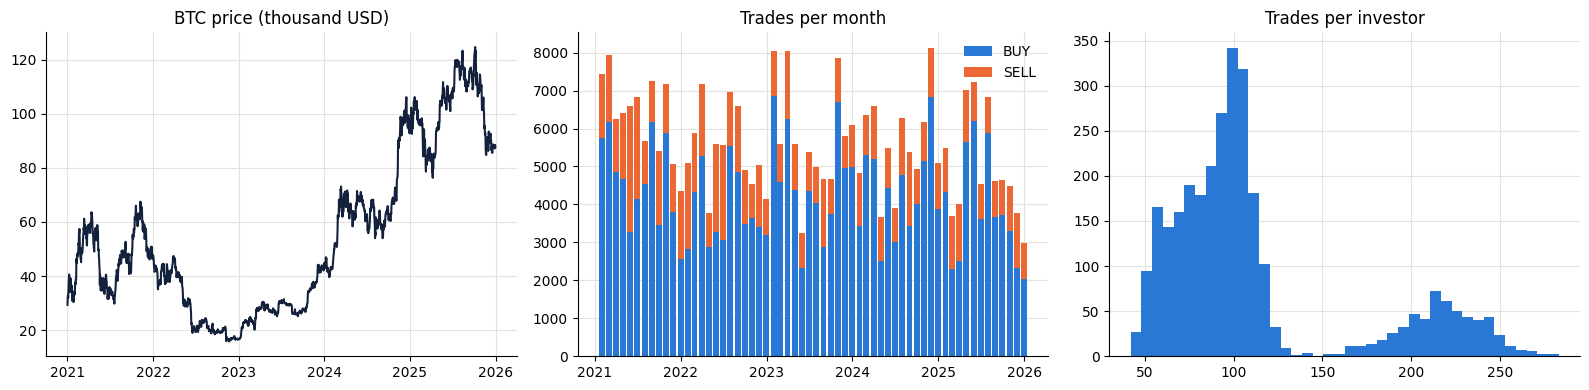

In [12]:
summary, by_side, by_year = describe_data(market_raw, trades_clean)
display(summary); display(by_side.round(0)); display(by_year.round(3))
plot_overview(market_raw, trades_clean)

### 9.5 Market context and cycle windows

Share of days by state (after warm-up):


,share
state,
normal,0.352
deep drawdown,0.168
fast drop,0.150
near peak,0.146
hot + near peak,0.123
hot,0.061


16 cycles | length 33-260 days, median 109


,cycle_id,window_start,window_end,n_days,is_warmup,is_open,mkt_hot_share,mkt_near_share,mkt_return
0,0,2021-01-01,2021-02-02,33,True,False,0.000,0.000,0.072
1,1,2021-02-03,2021-06-13,131,False,False,0.206,0.176,0.037
2,2,2021-06-14,2021-07-25,42,False,False,0.048,0.000,-0.127
3,3,2021-07-26,2021-12-23,151,False,False,0.212,0.318,0.365
4,4,2021-12-24,2022-01-28,36,False,False,0.083,0.000,-0.258
5,5,2022-01-29,2022-05-29,121,False,False,0.149,0.099,-0.228
6,6,2022-05-30,2022-09-09,103,False,False,0.078,0.165,-0.327
7,7,2022-09-10,2022-10-25,46,False,False,0.065,0.000,-0.072
8,8,2022-10-26,2023-01-10,77,False,False,0.052,0.143,-0.160
9,9,2023-01-11,2023-06-19,160,False,False,0.250,0.406,0.496


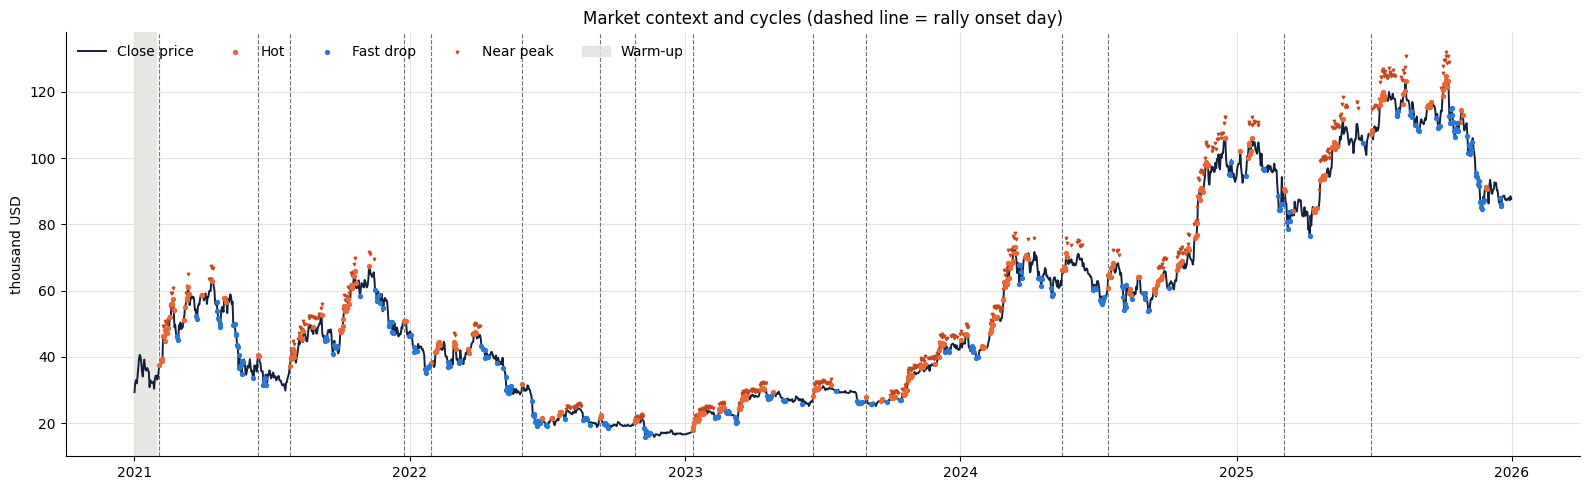

,ONSET_GAP_DAYS,cycles,shortest,median,longest
0,21,25,26,70,160
1,30,16,33,109,260
2,45,10,33,140,536
3,60,4,33,353,1086


In [13]:
states = market_states(market_raw, P)
cycles = build_cycles(states, P)
cycle_mkt = cycle_market_summary(states, cycles)
print("Share of days by state (after warm-up):")
display(states.loc[~states["warmup"], "state"].value_counts(normalize=True).round(3).to_frame("share"))
print(f"{len(cycles)} cycles | length {cycles['n_days'].min()}-{cycles['n_days'].max()} days, median {cycles['n_days'].median():.0f}")
tab = cycle_mkt[["cycle_id", "window_start", "window_end", "n_days", "is_warmup", "is_open",
                 "mkt_hot_share", "mkt_near_share", "mkt_return"]].copy()
tab[["mkt_hot_share", "mkt_near_share", "mkt_return"]] = tab[["mkt_hot_share", "mkt_near_share", "mkt_return"]].round(3)
display(tab)
plot_market_context(states, cycles)

# Sensitivity of the cycle split to ONSET_GAP_DAYS (changes boundaries only, no scoring)
sens = []
for gap in [21, 30, 45, 60]:
    cy = build_cycles(states, {**P, "ONSET_GAP_DAYS": gap})
    sens.append({"ONSET_GAP_DAYS": gap, "cycles": len(cy), "shortest": cy["n_days"].min(),
                 "median": int(cy["n_days"].median()), "longest": cy["n_days"].max()})
pd.DataFrame(sens)

### 9.6 Compute features

In [14]:
t0 = time.time()
tl, quiet_events = trade_features(trades_clean, states, cycles, P)
w = window_features(tl, quiet_events, cycle_mkt, P)
print(f"{len(w):,} investor x cycle pairs | {time.time() - t0:.0f}s")
n_trades_cycle = w.loc[~w["is_warmup"], "n_trades"]
print(f"Trades / investor / cycle: median {n_trades_cycle.median():.0f}, empty cycles {(n_trades_cycle == 0).mean():.1%}")
w[FEAT].describe().T.round(3)

47,406 investor x cycle pairs | 25s
Trades / investor / cycle: median 5, empty cycles 3.7%


,count,mean,std,min,25%,50%,75%,max
f01_dormancy_before_trigger,22159.0,0.309,1.044,-3.629,-0.427,0.348,1.099,3.742
f02_trigger_vs_own_rate,41332.0,0.864,0.900,-2.508,0.332,0.913,1.431,4.689
f03_price_novelty,36339.0,-0.004,0.366,-0.926,-0.352,0.032,0.318,0.809
f04_trigger_size_uplift,22638.0,0.013,0.395,-2.614,-0.186,0.011,0.208,2.722
f05_near_peak_dose_response,22488.0,0.003,0.419,-1.000,-0.286,0.000,0.290,1.000
f06_near_peak_share_excess,34229.0,0.065,0.282,-0.450,-0.165,0.037,0.253,0.901
f07_near_peak_net_flow,25079.0,0.016,0.251,-0.829,-0.125,0.042,0.173,0.830
f08_hot_week_burst_ratio,26547.0,1.275,0.463,-0.367,0.938,1.282,1.604,2.829
f09_burst_buy_skew,12706.0,-0.044,0.201,-0.750,-0.150,-0.008,0.088,0.614
f10_cash_hoard_vs_own,20203.0,-0.109,0.150,-0.546,-0.223,-0.128,-0.019,0.813


### 9.7 Composite FOMO score

In [15]:
t0 = time.time()
res, contrib, model_log = score_cycles(w, P)
inv = investor_rollup(res, contrib, P)
sub_full, sub_cycles = make_submissions(res, inv)
use = (res["n_trades"] > 0) & ~res["is_warmup"]
print(f"Scoring finished in {time.time() - t0:.0f}s")
print("Cycle level (with trades):", res.loc[use, "fomo_level"].value_counts(normalize=True).round(3).to_dict())
print("Whole period:", inv["fomo_level"].value_counts().to_dict(), "| score thresholds:", [round(x, 2) for x in inv.attrs["thresholds"]])
display(res.loc[use, ["feature_score", "hmm_score", "hmm_fomo_state_prob", "fomo_score", "confidence"]].describe().round(3))
display(res.loc[use, ["feature_score", "hmm_score"]].corr(method="spearman").round(3))
sub_full.head()

/tmp/ipykernel_2935/2630253525.py:132: RuntimeWarning: Mean of empty slice
  rowmean = np.nanmean(np.where(valid[:, :, None], X, np.nan), axis=2)
/tmp/ipykernel_2935/2630253525.py:147: RuntimeWarning: Mean of empty slice
  mu[k] = np.nanmean(xs, axis=0) if len(xs) else 0.5
/tmp/ipykernel_2935/2630253525.py:148: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var[k] = np.maximum(np.nanvar(xs, axis=0) if len(xs) > 1 else 0.05, var_floor)


/tmp/ipykernel_2935/2630253525.py:132: RuntimeWarning: Mean of empty slice
  rowmean = np.nanmean(np.where(valid[:, :, None], X, np.nan), axis=2)


/tmp/ipykernel_2935/2630253525.py:132: RuntimeWarning: Mean of empty slice
  rowmean = np.nanmean(np.where(valid[:, :, None], X, np.nan), axis=2)


/tmp/ipykernel_2935/2630253525.py:132: RuntimeWarning: Mean of empty slice
  rowmean = np.nanmean(np.where(valid[:, :, None], X, np.nan), axis=2)


/tmp/ipykernel_2935/2630253525.py:132: RuntimeWarning: Mean of empty slice
  rowmean = np.nanmean(np.where(valid[:, :, None], X, np.nan), axis=2)


...

/tmp/ipykernel_2935/2630253525.py:132: RuntimeWarning: Mean of empty slice
  rowmean = np.nanmean(np.where(valid[:, :, None], X, np.nan), axis=2)


Scoring finished in 75s
Cycle level (with trades): {'Low': 0.449, 'Medium': 0.396, 'High': 0.155}
Whole period: {'Low': 1500, 'Medium': 1200, 'High': 300} | score thresholds: [50.79, 61.22]


,feature_score,hmm_score,hmm_fomo_state_prob,fomo_score,confidence
count,43341.000,43341.000,43341.000,43341.000,43341.000
mean,0.396,0.378,0.386,38.714,0.693
std,0.182,0.158,0.476,16.409,0.168
min,0.075,0.137,0.000,10.610,0.078
25%,0.233,0.214,0.000,23.090,0.598
50%,0.368,0.397,0.000,37.880,0.715
75%,0.550,0.533,1.000,53.650,0.810
max,0.889,0.630,1.000,73.580,1.000


,feature_score,hmm_score
feature_score,1.000,0.855
hmm_score,0.855,1.000


,investor_id,window_start,window_end,fomo_score,fomo_level,confidence,top_1_signal,top_2_signal,top_3_signal,notes
0,INV_00001,2021-01-01,2025-12-31,61.61,High,0.480,f15_sequence_stages,f12_hot_notional_excess,f11_deploy_speed,High in 5/14 active cycles; peak cycle score 67.8
1,INV_00002,2021-01-01,2025-12-31,24.57,Low,0.961,f03_price_novelty,f05_near_peak_dose_response,none,High in 0/15 active cycles; peak cycle score 30.2
2,INV_00003,2021-01-01,2025-12-31,44.85,Low,0.982,f03_price_novelty,f02_trigger_vs_own_rate,f12_hot_notional_excess,High in 0/15 active cycles; peak cycle score 53.9
3,INV_00004,2021-01-01,2025-12-31,51.97,Medium,0.644,f15_sequence_stages,f12_hot_notional_excess,f03_price_novelty,High in 2/15 active cycles; peak cycle score 62.3
4,INV_00005,2021-01-01,2025-12-31,56.27,Medium,0.868,f13_post_peak_silence,f15_sequence_stages,f07_near_peak_net_flow,High in 4/15 active cycles; peak cycle score 67.9


### 9.7b Correlation matrix, dropped features and final weights

Column `eta2` is the share of variance explained by the market cycle; `weight_share` is the feature's share of the feature score in the last cycle (0 = dropped because of correlation).

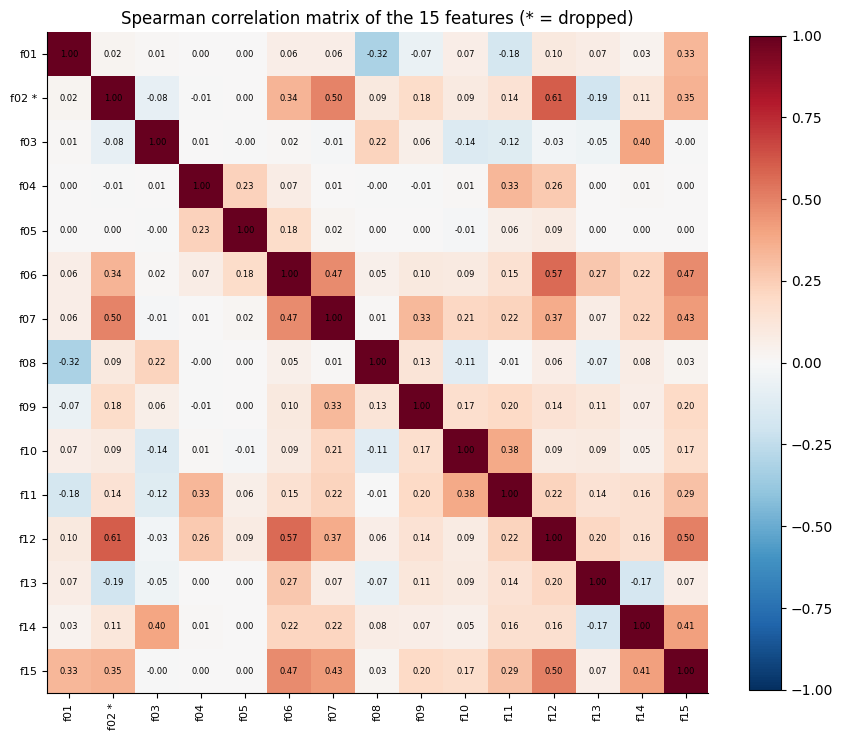

Pairs with |rho| >= CORR_TH on observed cells: [('f02_trigger_vs_own_rate', 'f12_hot_notional_excess', 0.61)]
Features dropped in the last cycle: ['f02_trigger_vs_own_rate']


,group,tag,active,eta2,weight_share
f01_dormancy_before_trigger,S1,P,True,0.138,0.058
f02_trigger_vs_own_rate,S1,P,False,0.131,0.000
f03_price_novelty,S1,P+M,True,0.677,0.022
f04_trigger_size_uplift,S1,P,True,0.143,0.058
f05_near_peak_dose_response,S2,M,True,0.000,0.067
f06_near_peak_share_excess,S2,M,True,0.015,0.066
f07_near_peak_net_flow,S2,P,True,0.117,0.059
f08_hot_week_burst_ratio,S3,P,True,0.334,0.067
f09_burst_buy_skew,S3,P,True,0.067,0.094
f10_cash_hoard_vs_own,S4,P,True,0.184,0.055


In [16]:
pct = normalize_features(w)
obs = observed_percentiles(w, pct)
rows = use.to_numpy()
last = model_log[max(model_log)]
C = plot_corr_matrix(obs, rows, last["active"], P)
wts = pd.Series(last["weights"])
ftab = pd.DataFrame({"group": [FEATURES[f][0] for f in FEAT], "tag": [FEATURES[f][1] for f in FEAT],
                     "active": [f in last["active"] for f in FEAT], "eta2": pd.Series(last["eta2"]).round(3),
                     "weight_share": (wts / wts.sum()).round(3)})
print("Pairs with |rho| >= CORR_TH on observed cells:", [(a, b, round(float(C.loc[a, b]), 2)) for i, a in enumerate(FEAT) for b in FEAT[i + 1:] if abs(C.loc[a, b]) >= P["CORR_TH"]])
print("Features dropped in the last cycle:", sorted(set(FEAT) - set(last["active"])))
ftab

### 9.8 Visualize results

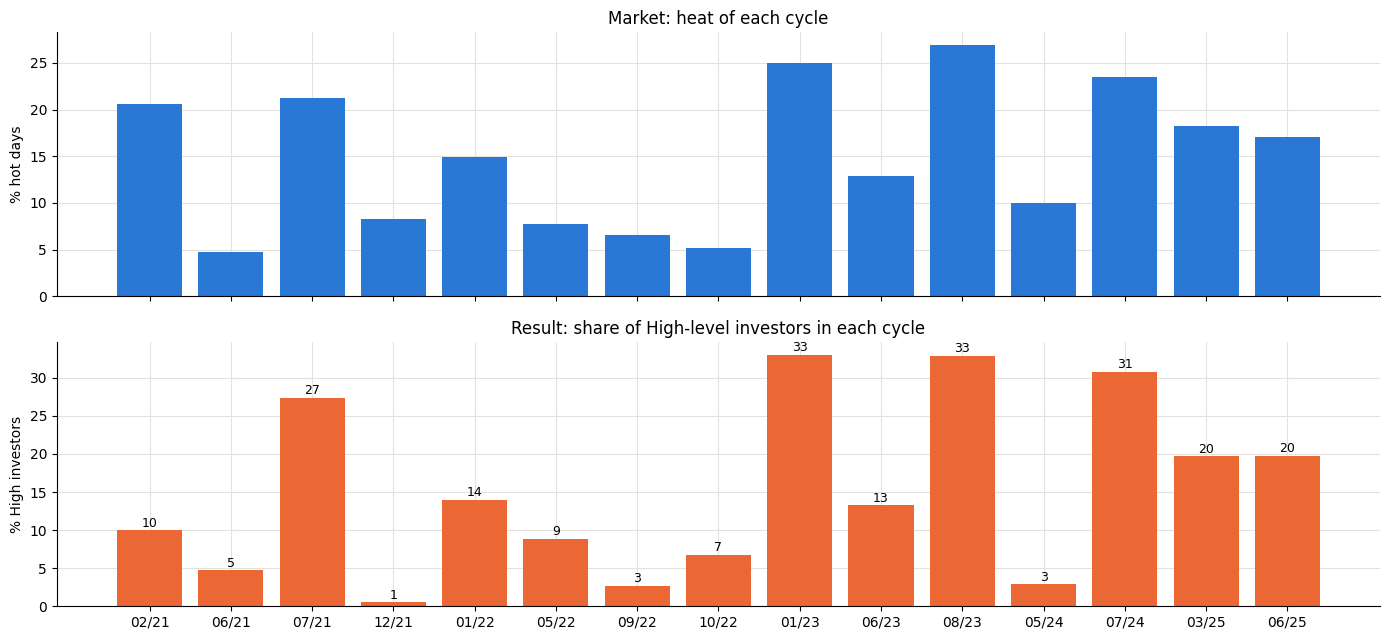

Rank correlation between % hot days and % High investors by cycle: 0.87


,window_start,window_end,n_days,mkt_hot_share,mkt_return,score,high
cycle_id,,,,,,,
1,2021-02-03,2021-06-13,131,0.206,0.037,35.186,0.100
2,2021-06-14,2021-07-25,42,0.048,-0.127,28.366,0.047
3,2021-07-26,2021-12-23,151,0.212,0.365,47.456,0.274
4,2021-12-24,2022-01-28,36,0.083,-0.258,26.782,0.005
5,2022-01-29,2022-05-29,121,0.149,-0.228,41.202,0.140
6,2022-05-30,2022-09-09,103,0.078,-0.327,38.101,0.089
7,2022-09-10,2022-10-25,46,0.065,-0.072,30.014,0.027
8,2022-10-26,2023-01-10,77,0.052,-0.160,31.410,0.068
9,2023-01-11,2023-06-19,160,0.250,0.496,48.686,0.330


In [17]:
cycle_table, rho = plot_cycle_results(res[use], cycle_mkt)
print(f"Rank correlation between % hot days and % High investors by cycle: {rho:.2f}")
cycle_table

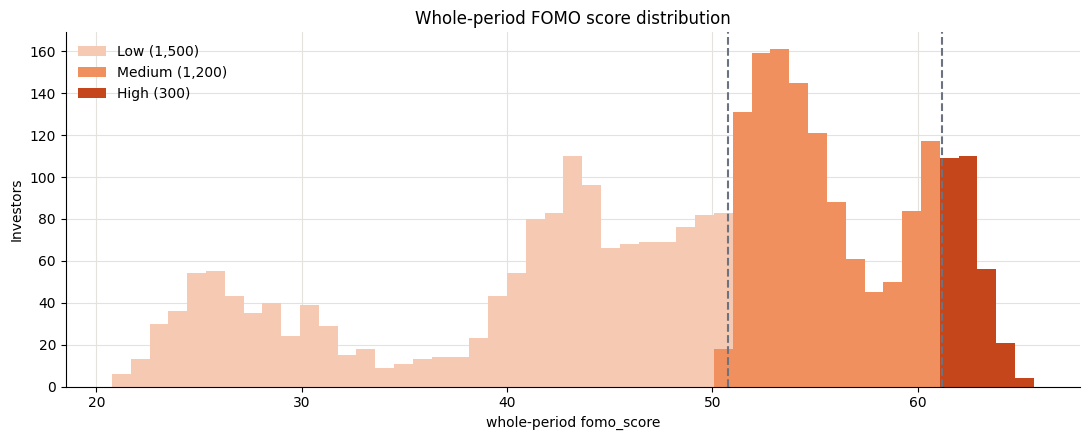

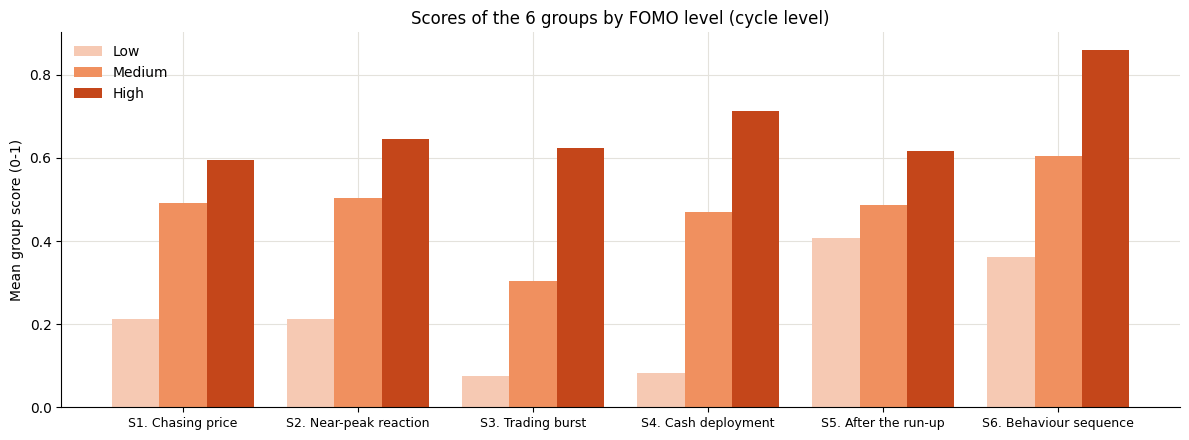

,Chasing price,Near-peak reaction,Trading burst,Cash deployment,After the run-up,Behaviour sequence
fomo_level,,,,,,
Low,0.212,0.213,0.076,0.083,0.406,0.362
Medium,0.491,0.503,0.305,0.470,0.486,0.605
High,0.595,0.646,0.624,0.714,0.616,0.859


In [18]:
plot_score_distribution(inv, P)
plot_groups_by_level(res[use])

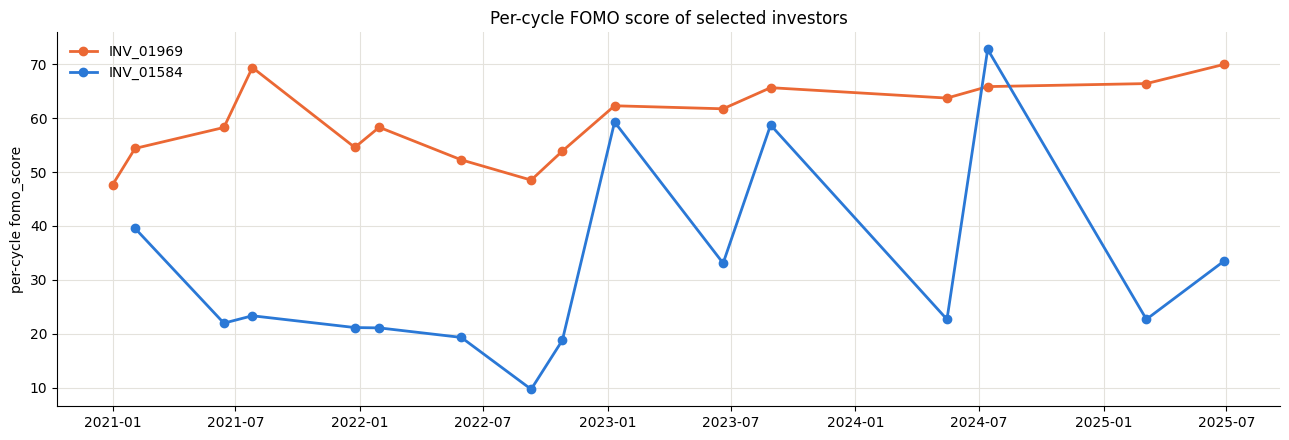

,investor_id,window_start,window_end,fomo_score,fomo_level,confidence,top_1_signal,top_2_signal,top_3_signal,notes
1583,INV_01584,2021-01-01,2025-12-31,51.23,Medium,0.548,f15_sequence_stages,f05_near_peak_dose_response,f02_trigger_vs_own_rate,High in 2/14 active cycles; peak cycle score 72.8
1968,INV_01969,2021-01-01,2025-12-31,65.67,High,0.782,f15_sequence_stages,f13_post_peak_silence,f12_hot_notional_excess,High in 11/15 active cycles; peak cycle score ...


In [19]:
# Example: the highest-scoring investor and the investor with the largest score spread across cycles
top_inv = inv.sort_values("fomo_score", ascending=False)["investor_id"].iloc[0]
spread = res[use].groupby("investor_id")["fomo_score"].agg(lambda x: x.max() - x.median())
var_inv = spread.drop(top_inv).idxmax()
plot_investor_timeline(res, [top_inv, var_inv], P)
inv[inv["investor_id"].isin([top_inv, var_inv])][SUB_COLS]

### 9.9 Data-leakage check

In [20]:
if P["RUN_LEAKAGE_CHECK"]:
    full_out = dict(results=res, cycles=cycles)
    display(leakage_check(market_raw, trades_raw, P, full_out, P["LEAKAGE_CUTOFF"]).to_frame("result"))

/tmp/ipykernel_2935/2630253525.py:132: RuntimeWarning: Mean of empty slice
  rowmean = np.nanmean(np.where(valid[:, :, None], X, np.nan), axis=2)
/tmp/ipykernel_2935/2630253525.py:147: RuntimeWarning: Mean of empty slice
  mu[k] = np.nanmean(xs, axis=0) if len(xs) else 0.5
/tmp/ipykernel_2935/2630253525.py:148: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var[k] = np.maximum(np.nanvar(xs, axis=0) if len(xs) > 1 else 0.05, var_floor)


/tmp/ipykernel_2935/2630253525.py:132: RuntimeWarning: Mean of empty slice
  rowmean = np.nanmean(np.where(valid[:, :, None], X, np.nan), axis=2)


/tmp/ipykernel_2935/2630253525.py:132: RuntimeWarning: Mean of empty slice
  rowmean = np.nanmean(np.where(valid[:, :, None], X, np.nan), axis=2)


/tmp/ipykernel_2935/2630253525.py:132: RuntimeWarning: Mean of empty slice
  rowmean = np.nanmean(np.where(valid[:, :, None], X, np.nan), axis=2)


/tmp/ipykernel_2935/2630253525.py:132: RuntimeWarning: Mean of empty slice
  rowmean = np.nanmean(np.where(valid[:, :, None], X, np.nan), axis=2)


...

/tmp/ipykernel_2935/2630253525.py:132: RuntimeWarning: Mean of empty slice
  rowmean = np.nanmean(np.where(valid[:, :, None], X, np.nan), axis=2)


/tmp/ipykernel_2935/2630253525.py:132: RuntimeWarning: Mean of empty slice
  rowmean = np.nanmean(np.where(valid[:, :, None], X, np.nan), axis=2)


/tmp/ipykernel_2935/2630253525.py:132: RuntimeWarning: Mean of empty slice
  rowmean = np.nanmean(np.where(valid[:, :, None], X, np.nan), axis=2)


/tmp/ipykernel_2935/2630253525.py:132: RuntimeWarning: Mean of empty slice
  rowmean = np.nanmean(np.where(valid[:, :, None], X, np.nan), axis=2)


,result
cutoff,2023-06-30
closed cycles compared,10
rows compared,29406
cycle boundaries identical,True
max abs difference,0.0
passed,True


### 9.10 Write the submission files

In [21]:
out = Path(P["OUT_DIR"]); (out / "submit").mkdir(parents=True, exist_ok=True); (out / "result").mkdir(parents=True, exist_ok=True)
sub_full.to_csv(out / "submit" / "SAMPLE_SUBMISSION.csv", index=False)
sub_cycles.to_csv(out / "submit" / "submission_cycles.csv", index=False)
inv.to_csv(out / "result" / "investor_level_scores.csv", index=False)
cycle_mkt.to_csv(out / "result" / "cycles.csv", index=False)
(out / "parameters.json").write_text(json.dumps(P, indent=2, default=str))
print("Written:", sorted(str(p.relative_to(out)) for p in out.rglob("*") if p.is_file()))
print("SAMPLE_SUBMISSION:", sub_full.shape, "| submission_cycles:", sub_cycles.shape)

Written: ['model/feature_corr_observed.csv', 'model/feature_corr_zero_filled.csv', 'model/feature_table.csv', 'model/lr_coefficients.csv', 'parameters.json', 'result/cycles.csv', 'result/investor_cycle_features_scores.csv.gz', 'result/investor_level_scores.csv', 'submit/SAMPLE_SUBMISSION.csv', 'submit/submission_cycles.csv', 'validate/validation_report.json', 'validate/validation_synthetic_investors.csv']
SAMPLE_SUBMISSION: (3000, 10) | submission_cycles: (47406, 10)


## Appendix

HMM diagnostics, label-free validation results (sensitivity, synthetic investors, sanity checks, edge cases), limitations and the `validate.py` code are in the separate notebook **`FOMO_appendix.ipynb`**. That notebook only reads the `validation_report.json` written by `validate.py` and does not need to re-run the pipeline. The data-leakage check runs directly in section 9.9 of this notebook.